# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ryan Fang, Eloise McDonough, Sufyan Billel

**Date:** 11/16/2026

In [1]:
# Your Phase 1 solution to the problem goes here.


# Q1:

Original dataset shape: (299, 13)
Duplicate rows: 0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Missing values per column:


age_nan                         0
creatinine_phosphokinase_nan    0
ejection_fraction_nan           0
platelets_nan                   0
serum_creatinine_nan            0
serum_sodium_nan                0
time_nan                        0
anaemia_nan                     0
diabetes_nan                    0
high_blood_pressure_nan         0
sex_nan                         0
smoking_nan                     0
DEATH_EVENT_nan                 0
dtype: int64


Target variable (DEATH_EVENT) counts and death rate:
DEATH_EVENT_clean
0    203
1     96
Name: count, dtype: int64
Overall proportion of deaths: 0.3211

Cross-tabulation of DEATH_EVENT by high_blood_pressure:


high_blood_pressure_clean,0,1
DEATH_EVENT_clean,,
0,137,66
1,57,39



Median follow-up time (days) by DEATH_EVENT:
DEATH_EVENT_clean
0    172.0
1     44.5
Name: time_clean, dtype: float64
Correlation between follow-up time and DEATH_EVENT: -0.527

Most frequent values in continuous lab and age columns:
  platelets_clean: {263358.03: 25, 237000.0: 4, 228000.0: 4}
  creatinine_phosphokinase_clean: {582: 47, 129: 4, 66: 4}
  age_clean: {60.0: 33, 50.0: 27, 65.0: 26}


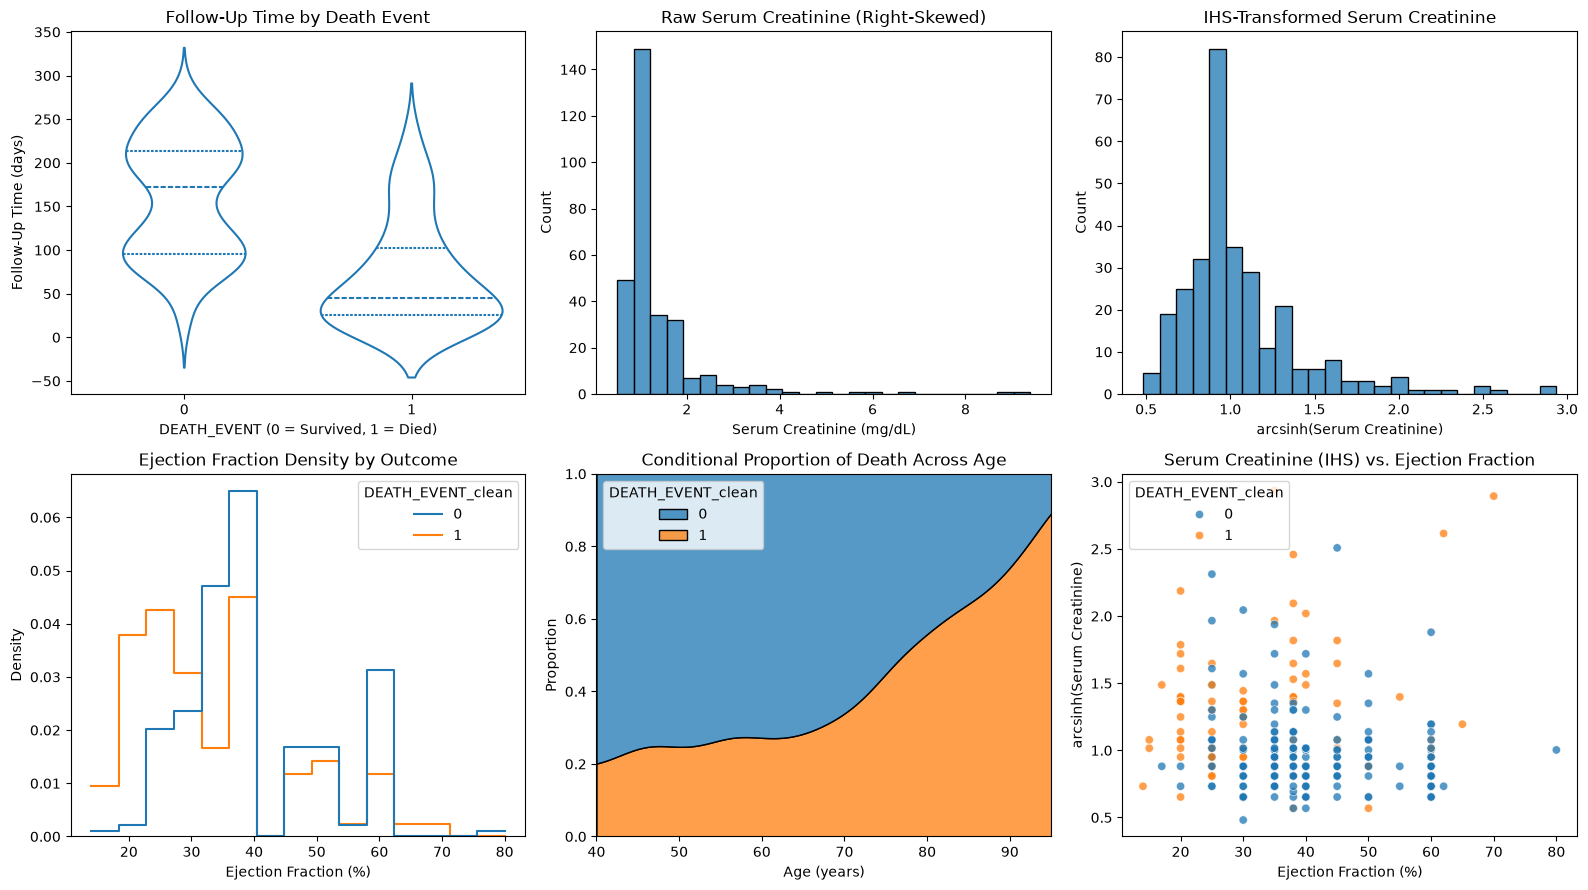


Cleaned feature matrix X shape: (299, 11)
Summary statistics of cleaned features:


,age,anaemia,creatinine_phosphokinase_ihs,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine_ihs,serum_sodium,sex,smoking
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,6.35,0.42,38.08,0.35,263358.03,1.05,136.63,0.65,0.32
std,11.89,0.50,1.13,0.49,11.83,0.48,97804.24,0.38,4.41,0.48,0.47
min,40.00,0.00,3.83,0.00,14.00,0.00,25100.00,0.48,113.00,0.00,0.00
25%,51.00,0.00,5.45,0.00,30.00,0.00,212500.00,0.81,134.00,0.00,0.00
50%,60.00,0.00,6.21,0.00,38.00,0.00,262000.00,0.95,137.00,1.00,0.00
75%,70.00,1.00,7.06,1.00,45.00,1.00,303500.00,1.14,140.00,1.00,1.00
max,95.00,1.00,9.66,1.00,80.00,1.00,850000.00,2.94,148.00,1.00,1.00


Correlations of cleaned features with DEATH_EVENT:


ejection_fraction              -0.2686
serum_sodium                   -0.1952
platelets                      -0.0491
smoking                        -0.0126
sex                            -0.0043
diabetes                       -0.0019
creatinine_phosphokinase_ihs    0.0321
anaemia                         0.0663
high_blood_pressure             0.0794
age                             0.2537
serum_creatinine_ihs            0.3522
dtype: float64

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load the dataset (supports both repo directory structure and local folder)
if os.path.exists('data/heart_failure/heart_failure_clinical_records_dataset.csv'):
    data_path = 'data/heart_failure/heart_failure_clinical_records_dataset.csv'
elif os.path.exists('data/heart_failure.csv'):
    data_path = 'data/heart_failure.csv'
else:
    data_path = 'heart_failure_clinical_records_dataset.csv'

df = pd.read_csv(data_path)
print("Original dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
display(df.head())

# define continuous numeric columns and binary 0/1 indicator columns
num_cols = [
    'age', 'creatinine_phosphokinase', 'ejection_fraction',
    'platelets', 'serum_creatinine', 'serum_sodium', 'time'
]
bin_cols = [
    'anaemia', 'diabetes', 'high_blood_pressure',
    'sex', 'smoking', 'DEATH_EVENT'
]

# coerce variables to numeric and track missingness with _nan indicator columns
for col in num_cols + bin_cols:
    df[f'{col}_clean'] = pd.to_numeric(df[col], errors='coerce')
    df[f'{col}_nan'] = df[f'{col}_clean'].isnull()

print("\nMissing values per column:")
display(df[[f'{c}_nan' for c in num_cols + bin_cols]].sum())

# inspect the target variable distribution and cross-tabulations
print("\nTarget variable (DEATH_EVENT) counts and death rate:")
print(df['DEATH_EVENT_clean'].value_counts())
print("Overall proportion of deaths:", round(df['DEATH_EVENT_clean'].mean(), 4))

print("\nCross-tabulation of DEATH_EVENT by high_blood_pressure:")
display(pd.crosstab(df['DEATH_EVENT_clean'], df['high_blood_pressure_clean']))

# inspect follow-up time by outcome to check for target leakage
print("\nMedian follow-up time (days) by DEATH_EVENT:")
print(df.groupby('DEATH_EVENT_clean')['time_clean'].median())
print("Correlation between follow-up time and DEATH_EVENT:", round(df['time_clean'].corr(df['DEATH_EVENT_clean']), 4))

# check frequent repeated values that reflect prior mean imputation in the raw data
print("\nMost frequent values in continuous lab and age columns:")
for col in ['platelets_clean', 'creatinine_phosphokinase_clean', 'age_clean']:
    print(f"  {col}: {df[col].value_counts().head(3).to_dict()}")

# apply inverse hyperbolic sine (arcsinh) transformation to heavily right-skewed lab variables
df['creatinine_phosphokinase_ihs'] = np.arcsinh(df['creatinine_phosphokinase_clean'])
df['serum_creatinine_ihs'] = np.arcsinh(df['serum_creatinine_clean'])

# EDA visualizations using course slide plot types
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# 1. Violin plot of follow-up time by DEATH_EVENT showing outcome leakage
sns.violinplot(data=df, x='DEATH_EVENT_clean', y='time_clean', inner='quart', fill=False, ax=axes[0, 0])
axes[0, 0].set(
    title='Follow-Up Time by Death Event',
    xlabel='DEATH_EVENT (0 = Survived, 1 = Died)',
    ylabel='Follow-Up Time (days)'
)

# 2. Raw vs arcsinh-transformed serum_creatinine histogram
sns.histplot(data=df, x='serum_creatinine_clean', bins=25, ax=axes[0, 1])
axes[0, 1].set(
    title='Raw Serum Creatinine (Right-Skewed)',
    xlabel='Serum Creatinine (mg/dL)',
    ylabel='Count'
)

sns.histplot(data=df, x='serum_creatinine_ihs', bins=25, ax=axes[0, 2])
axes[0, 2].set(
    title='IHS-Transformed Serum Creatinine',
    xlabel='arcsinh(Serum Creatinine)',
    ylabel='Count'
)

# 3. Layered step density histogram of ejection_fraction conditioned on DEATH_EVENT
sns.histplot(
    data=df, x='ejection_fraction_clean', hue='DEATH_EVENT_clean',
    stat='density', common_norm=False, multiple='layer', element='step', fill=False, ax=axes[1, 0]
)
axes[1, 0].set(
    title='Ejection Fraction Density by Outcome',
    xlabel='Ejection Fraction (%)',
    ylabel='Density'
)

# 4. Stacked KDE plot of age conditioned on DEATH_EVENT
sns.kdeplot(data=df, x='age_clean', hue='DEATH_EVENT_clean', multiple='fill', cut=0, ax=axes[1, 1])
axes[1, 1].set(
    title='Conditional Proportion of Death Across Age',
    xlabel='Age (years)',
    ylabel='Proportion'
)

# 5. Scatterplot of ejection_fraction vs serum_creatinine_ihs colored by DEATH_EVENT
sns.scatterplot(
    data=df, x='ejection_fraction_clean', y='serum_creatinine_ihs',
    hue='DEATH_EVENT_clean', alpha=0.75, ax=axes[1, 2]
)
axes[1, 2].set(
    title='Serum Creatinine (IHS) vs. Ejection Fraction',
    xlabel='Ejection Fraction (%)',
    ylabel='arcsinh(Serum Creatinine)'
)

plt.tight_layout()
plt.show()

# construct the cleaned feature matrix X (dropping time due to outcome leakage) and target y
clean_feature_Map = {
    'age_clean': 'age',
    'anaemia_clean': 'anaemia',
    'creatinine_phosphokinase_ihs': 'creatinine_phosphokinase_ihs',
    'diabetes_clean': 'diabetes',
    'ejection_fraction_clean': 'ejection_fraction',
    'high_blood_pressure_clean': 'high_blood_pressure',
    'platelets_clean': 'platelets',
    'serum_creatinine_ihs': 'serum_creatinine_ihs',
    'serum_sodium_clean': 'serum_sodium',
    'sex_clean': 'sex',
    'smoking_clean': 'smoking'
}

X = df[list(clean_feature_Map.keys())].rename(columns=clean_feature_Map).copy()
y = df['DEATH_EVENT_clean'].copy()
features = list(X.columns)

print(f"\nCleaned feature matrix X shape: {X.shape}")
print("Summary statistics of cleaned features:")
display(X.describe().round(2))

print("Correlations of cleaned features with DEATH_EVENT:")
display(X.apply(lambda s: s.corr(y)).sort_values().round(4))

The raw heart failure dataset has 299 patients and 13 columns with no missing values and no duplicate rows. The outcome variable `DEATH_EVENT` equals 1 for the 96 patients who died during the study and 0 for the 203 patients who survived, which gives a death rate of 32.11 percent. Five features are already 0 and 1 indicators for anaemia, diabetes, high blood pressure, sex, and smoking, so they do not need any extra encoding.

We made three main decisions while cleaning the numeric variables. First, we dropped `time` because it measures follow-up days until a patient dies or leaves the study. Patients who died had a median follow-up of 44.5 days compared to 172.0 days for survivors, giving a correlation of -0.5270 with death. A doctor cannot know follow-up length at the start of care, so keeping `time` would leak the answer into the models. Second, we applied the inverse hyperbolic sine transform to `creatinine_phosphokinase` and `serum_creatinine`. Both lab values have heavy right tails, with `creatinine_phosphokinase` reaching up to 7,861 against a median of 250.0 and `serum_creatinine` reaching 9.4 against a median of 1.10. Transforming them keeps extreme outliers from pulling on the linear model slopes. Third, we checked repeated numbers in the continuous columns. A platelet count of 263,358.03 shows up 25 times and equals the exact column mean, while a `creatinine_phosphokinase` value of 582 shows up 47 times. Those values were filled in by whoever created the original dataset, and we kept those rows so we would not lose up to 72 patients from a 299-row dataset.

Across the 11 cleaned features, transformed serum creatinine has the strongest positive correlation with death at 0.3522, followed by age at 0.2537. Ejection fraction has the strongest negative correlation at -0.2686, followed by serum sodium at -0.1952.

# Q2:

Training set shape: X_train0 = (239, 11), y_train0 = (239,)
Test set shape:     X_test0  = (60, 11),  y_test0  = (60,)

Question 2 Model Performance (Seed 3001):


,Model,Seed,Train RMSE,Test RMSE,Train R^2,Test R^2,Test Accuracy (p > 0.5)
0,Decision Tree (max_depth=3),3001,0.3710,0.4053,0.3820,0.1601,0.7500
1,Linear Regression (OLS),3001,0.4096,0.3959,0.2467,0.1985,0.7833


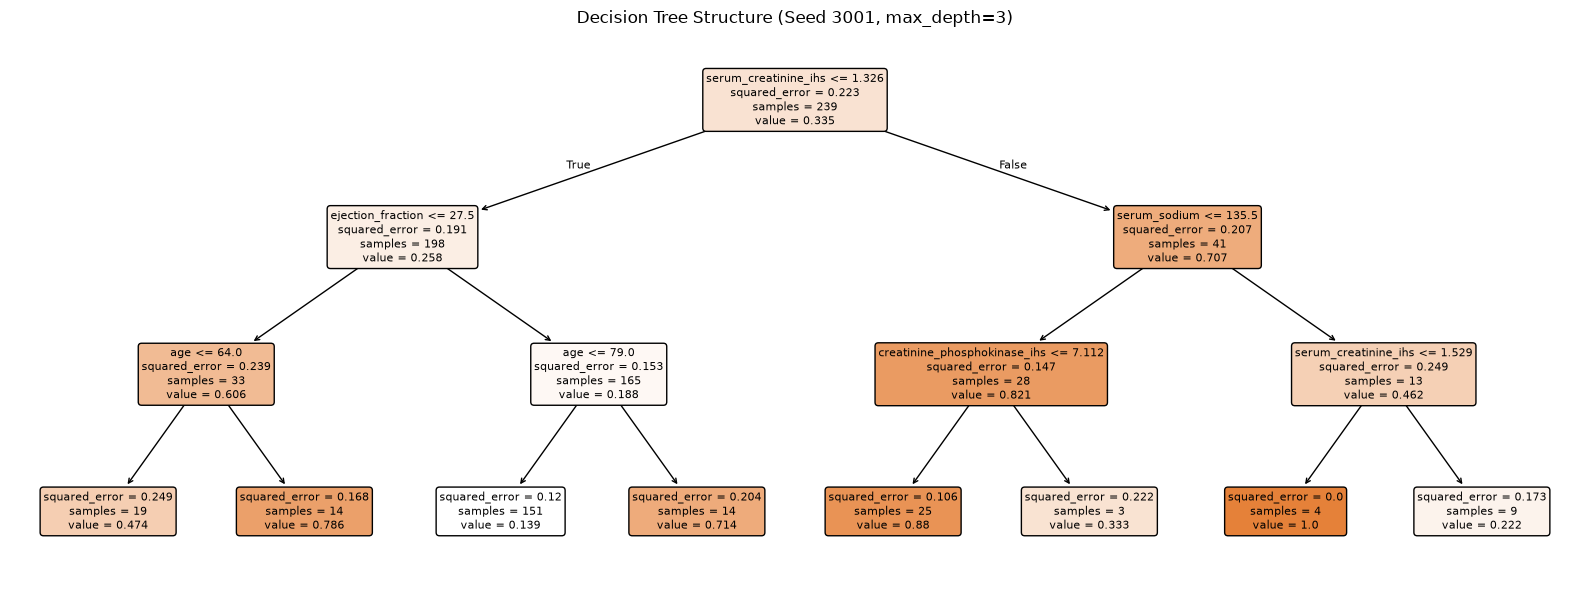

Text representation of the Question 2 Decision Tree:
|--- serum_creatinine_ihs <= 1.33
|   |--- ejection_fraction <= 27.50
|   |   |--- age <= 64.00
|   |   |   |--- value: [0.47]
|   |   |--- age >  64.00
|   |   |   |--- value: [0.79]
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.00
|   |   |   |--- value: [0.14]
|   |   |--- age >  79.00
|   |   |   |--- value: [0.71]
|--- serum_creatinine_ihs >  1.33
|   |--- serum_sodium <= 135.50
|   |   |--- creatinine_phosphokinase_ihs <= 7.11
|   |   |   |--- value: [0.88]
|   |   |--- creatinine_phosphokinase_ihs >  7.11
|   |   |   |--- value: [0.33]
|   |--- serum_sodium >  135.50
|   |   |--- serum_creatinine_ihs <= 1.53
|   |   |   |--- value: [1.00]
|   |   |--- serum_creatinine_ihs >  1.53
|   |   |   |--- value: [0.22]

Question 2 Linear Model Coefficients (Seed 3001):


sex                            -0.081955
serum_sodium                   -0.009998
ejection_fraction              -0.009760
platelets                      -0.000000
age                             0.008769
smoking                         0.029586
creatinine_phosphokinase_ihs    0.034670
anaemia                         0.046802
diabetes                        0.056883
high_blood_pressure             0.095363
serum_creatinine_ihs            0.346771
dtype: float64

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score, accuracy_score

# helper function to split data for a given seed and fit both a tree and a linear model
def fit_models(seed):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )
    tree = DecisionTreeRegressor(max_depth=3, random_state=100).fit(X_train, y_train)
    lm = LinearRegression().fit(X_train, y_train)
    return tree, lm, X_train, X_test, y_train, y_test

# perform 80/20 train-test split and fit models for our primary seed
main_seed = 3001
tree0, lm0, X_train0, X_test0, y_train0, y_test0 = fit_models(main_seed)

print(f"Training set shape: X_train0 = {X_train0.shape}, y_train0 = {y_train0.shape}")
print(f"Test set shape:     X_test0  = {X_test0.shape},  y_test0  = {y_test0.shape}")

# set aside test-set predictions from the Question 2 models
tree_pred0 = tree0.predict(X_test0)
lm_pred0 = lm0.predict(X_test0)

# evaluate performance on both training and test sets
q2_results = pd.DataFrame([
    {
        'Model': 'Decision Tree (max_depth=3)',
        'Seed': main_seed,
        'Train RMSE': root_mean_squared_error(y_train0, tree0.predict(X_train0)),
        'Test RMSE': root_mean_squared_error(y_test0, tree_pred0),
        'Train R^2': r2_score(y_train0, tree0.predict(X_train0)),
        'Test R^2': r2_score(y_test0, tree_pred0),
        'Test Accuracy (p > 0.5)': accuracy_score(y_test0, tree_pred0 > 0.5)
    },
    {
        'Model': 'Linear Regression (OLS)',
        'Seed': main_seed,
        'Train RMSE': root_mean_squared_error(y_train0, lm0.predict(X_train0)),
        'Test RMSE': root_mean_squared_error(y_test0, lm_pred0),
        'Train R^2': r2_score(y_train0, lm0.predict(X_train0)),
        'Test R^2': r2_score(y_test0, lm_pred0),
        'Test Accuracy (p > 0.5)': accuracy_score(y_test0, lm_pred0 > 0.5)
    }
])

print("\nQuestion 2 Model Performance (Seed 3001):")
display(q2_results.round(4))

# visualize the fitted Question 2 Decision Tree
plt.figure(figsize=(16, 6))
plot_tree(
    tree0, feature_names=features, filled=True,
    rounded=True, impurity=True, fontsize=8
)
plt.title(f"Decision Tree Structure (Seed {main_seed}, max_depth=3)")
plt.tight_layout()
plt.show()

print("Text representation of the Question 2 Decision Tree:")
print(export_text(tree0, feature_names=features))

print("Question 2 Linear Model Coefficients (Seed 3001):")
coef0_series = pd.Series(lm0.coef_, index=features).sort_values()
display(coef0_series.round(6))

We split the cleaned data 80/20 using seed 3001, which put 239 patients in the training set and 60 patients in the test set. We then fit a depth-3 regression tree and an ordinary least squares linear model on the training data and saved their predictions on the 60 test patients.

The decision tree predicts the average death rate in each leaf. It gets a training RMSE of 0.3710 and a training $R^2$ of 0.3820. On the test set, it gets a test RMSE of 0.4053, a test $R^2$ of 0.1601, and an accuracy of 0.7500 when we classify predicted probabilities above 0.5 as deaths. The tree splits first on transformed serum creatinine at 1.326, then splits on ejection fraction at 27.50 on the left branch and serum sodium at 135.50 on the right branch, finishing with 8 leaves.

The linear model gets a worse training fit with a training RMSE of 0.4096 and a training $R^2$ of 0.2467, but it beats the tree on the held-out test set with a test RMSE of 0.3959, a test $R^2$ of 0.1985, and a test accuracy of 0.7833. Its largest positive weights are on transformed serum creatinine at +0.3468, high blood pressure at +0.0954, diabetes at +0.0569, and anaemia at +0.0468, along with +0.0088 per year of age. Its negative weights are on sex at -0.0820, serum sodium at -0.0100, and ejection fraction at -0.0098.

# Q3:

Test Set Performance Across All 6 Seeds (Evaluated on Each Seed's Own Test Set):


,Tree Test RMSE,Tree Test R^2,Tree Test Acc,Linear Test RMSE,Linear Test R^2,Linear Test Acc
Seed,,,,,,
3001,0.4053,0.1601,0.7500,0.3959,0.1985,0.7833
1,0.3839,0.1762,0.7667,0.3813,0.1871,0.8167
2,0.4123,0.1628,0.7500,0.3936,0.2370,0.7833
3,0.4126,0.2341,0.7667,0.4315,0.1620,0.6833
4,0.4319,0.1119,0.7167,0.4358,0.0956,0.7333
11,0.4285,0.0958,0.8000,0.4276,0.0995,0.7167



Structural Summary of Fitted Decision Trees Across Seeds:


,Root Split,Left Child Split (Level 2),Right Child Split (Level 2),Leaves,Features Used
Seed,,,,,
3001,serum_creatinine_ihs <= 1.326,ejection_fraction <= 27.500,serum_sodium <= 135.500,8,5
1,serum_creatinine_ihs <= 1.166,ejection_fraction <= 27.500,serum_sodium <= 135.500,8,4
2,serum_creatinine_ihs <= 1.166,ejection_fraction <= 27.500,ejection_fraction <= 22.500,7,5
3,serum_creatinine_ihs <= 1.358,ejection_fraction <= 32.500,serum_sodium <= 135.500,8,6
4,serum_creatinine_ihs <= 1.358,ejection_fraction <= 32.500,serum_creatinine_ihs <= 1.466,7,4
11,ejection_fraction <= 32.500,ejection_fraction <= 22.500,age <= 79.500,8,4


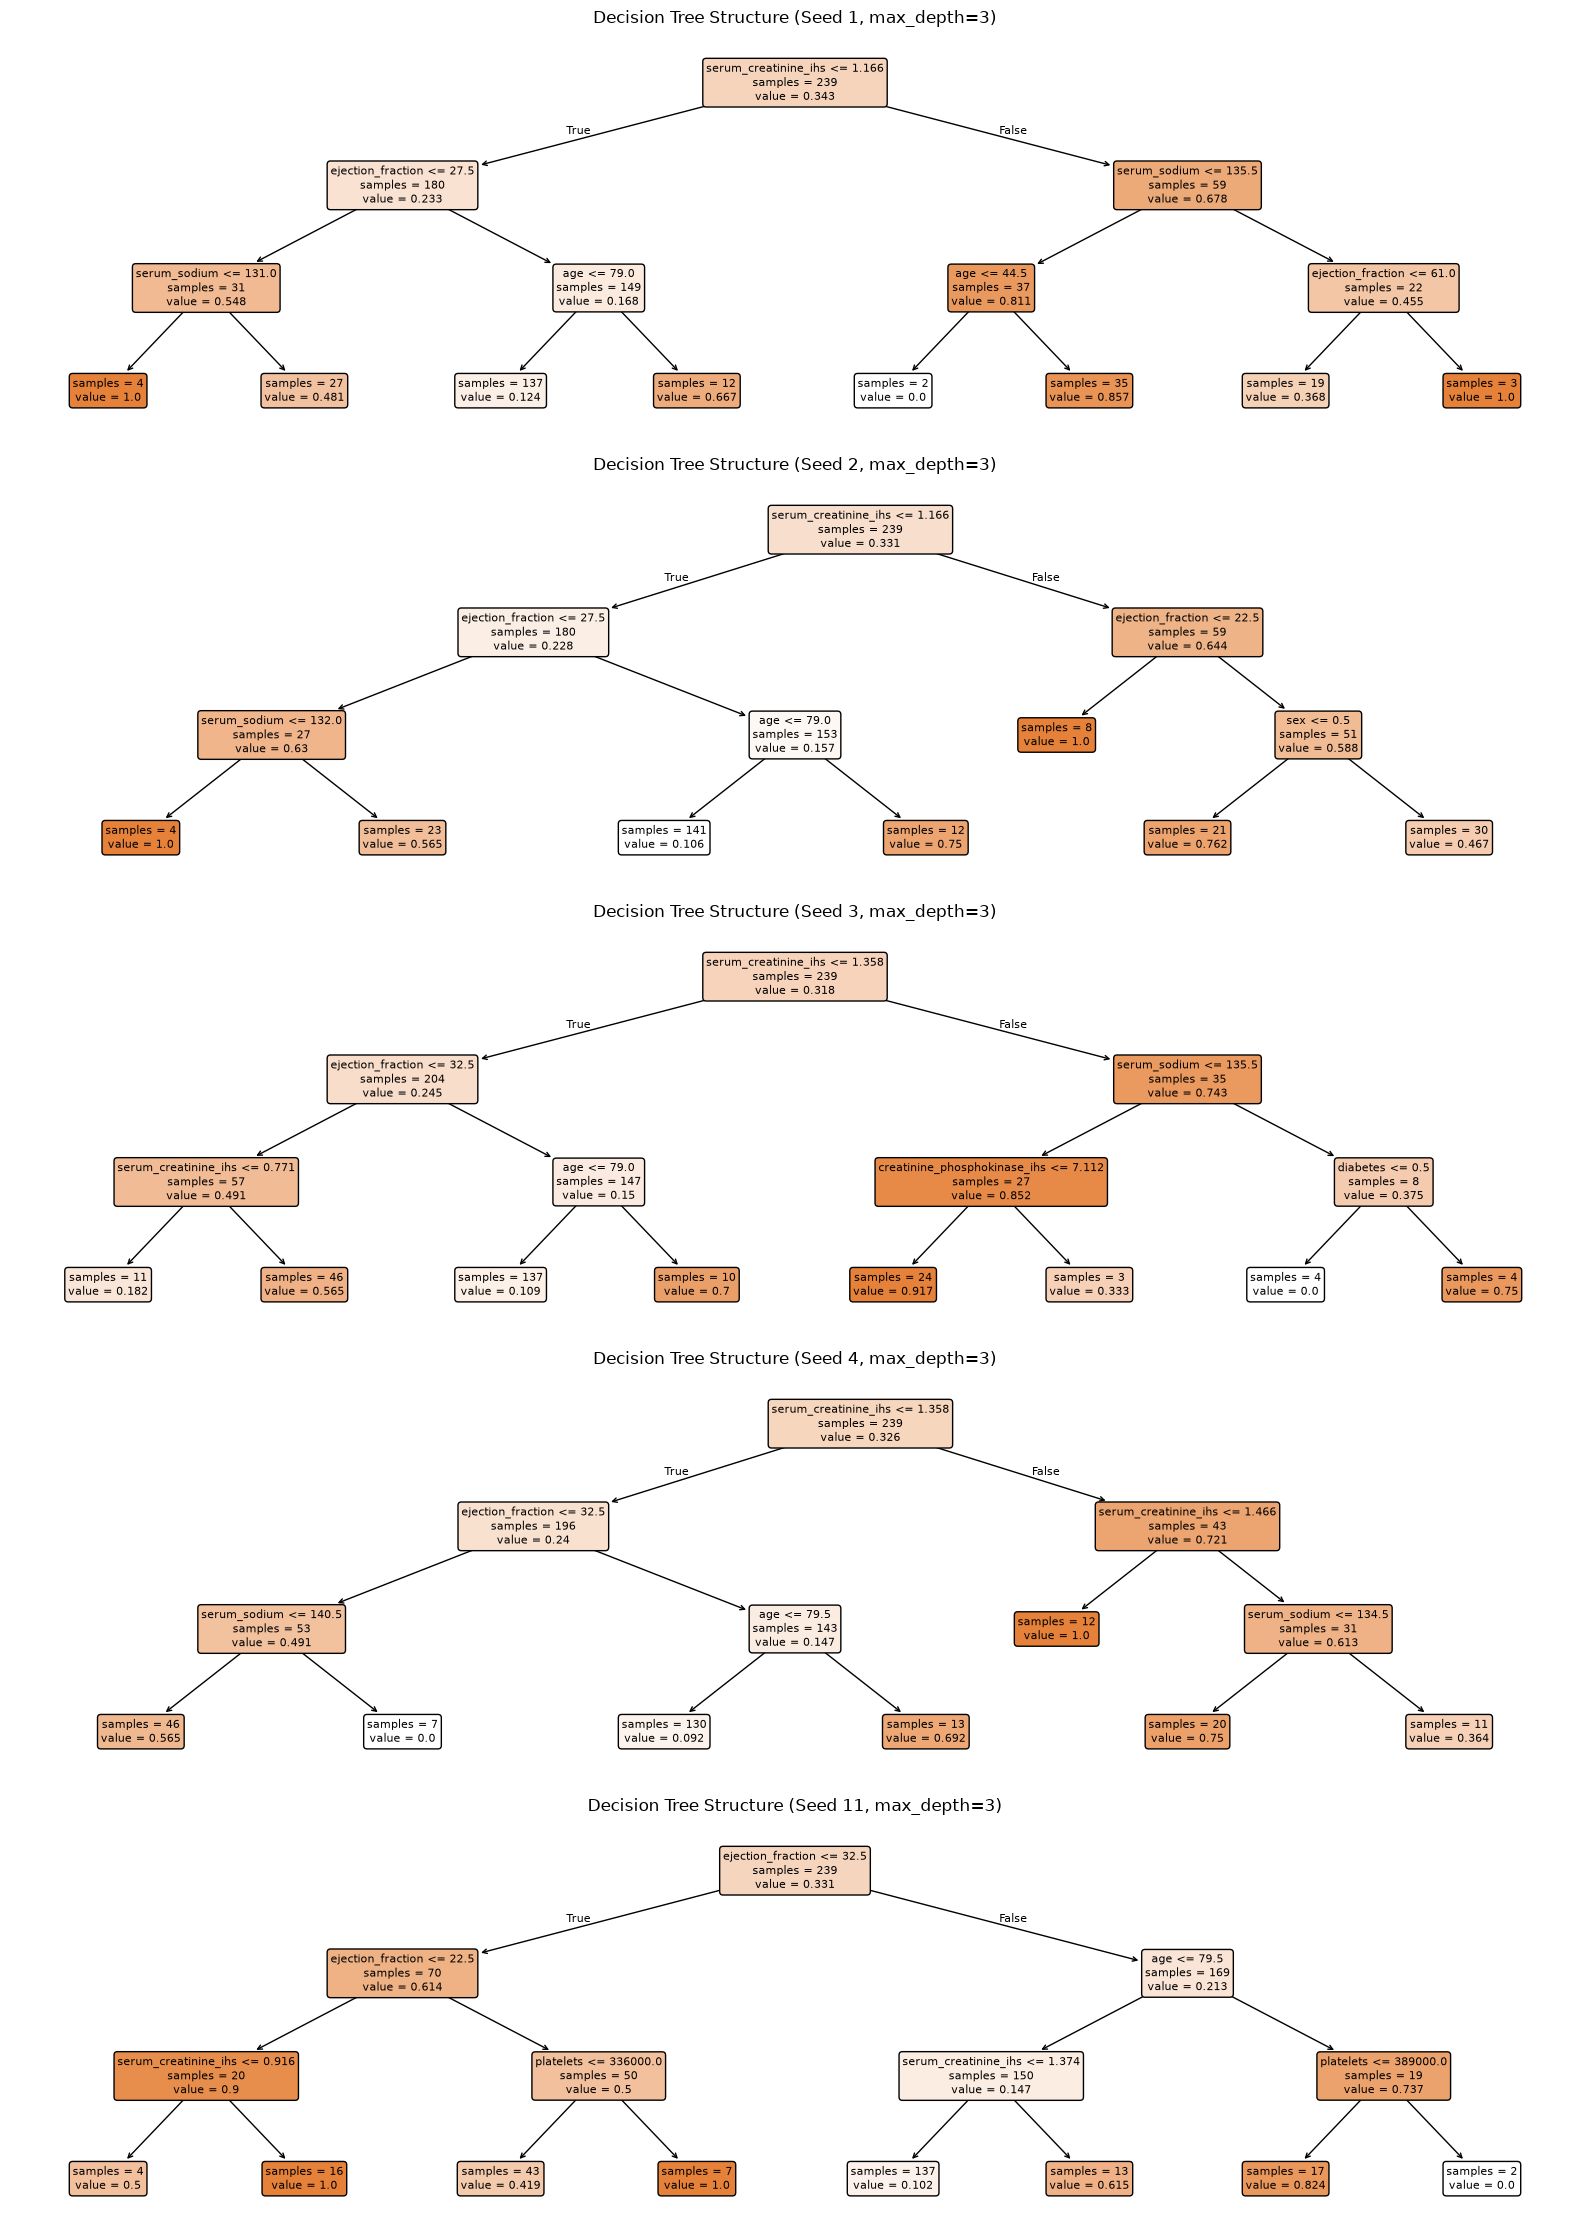

Linear Model Coefficients Across All 6 Seeds:


,3001,1,2,3,4,11,Mean,Std Dev,Min,Max
age,0.008769,0.007318,0.007757,0.008608,0.009696,0.009094,0.008540,0.000873,0.007318,0.009696
anaemia,0.046802,0.061603,0.066428,0.000562,0.059946,0.093806,0.054858,0.030774,0.000562,0.093806
creatinine_phosphokinase_ihs,0.034670,0.040025,0.039012,0.042694,0.020466,0.043705,0.036762,0.008591,0.020466,0.043705
diabetes,0.056883,0.050603,-0.013651,-0.006983,0.072416,-0.057871,0.016899,0.050815,-0.057871,0.072416
ejection_fraction,-0.009760,-0.008927,-0.008750,-0.009281,-0.009076,-0.010673,-0.009411,0.000709,-0.010673,-0.008750
high_blood_pressure,0.095363,0.051563,0.061679,0.080722,0.072960,0.074593,0.072813,0.015164,0.051563,0.095363
platelets,-0.000000,-0.000000,-0.000000,0.000000,-0.000000,0.000000,-0.000000,0.000000,-0.000000,0.000000
serum_creatinine_ihs,0.346771,0.361715,0.359247,0.357377,0.341793,0.225822,0.332121,0.052644,0.225822,0.361715
serum_sodium,-0.009998,-0.009783,-0.007347,-0.010122,-0.008513,-0.009678,-0.009240,0.001091,-0.010122,-0.007347
sex,-0.081955,-0.056883,-0.069931,-0.051181,-0.017093,-0.005283,-0.047054,0.029992,-0.081955,-0.005283


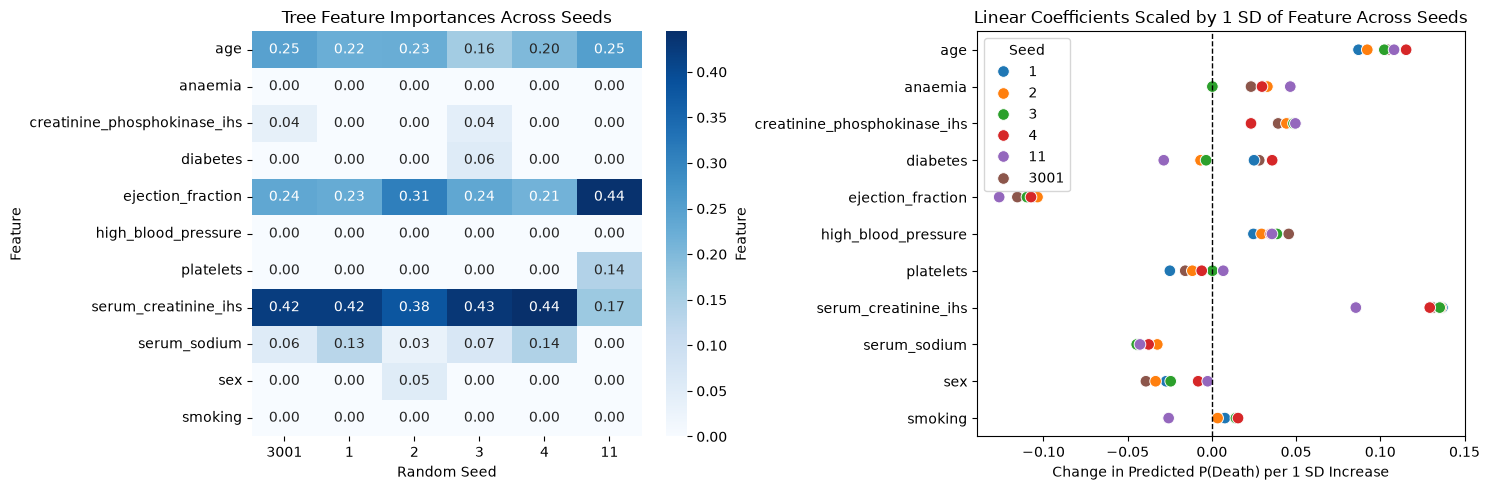

In [4]:
# repeat Step 2 across 5 different saved random seeds
alt_seeds = [1, 2, 3, 4, 11]
all_seeds = [main_seed] + alt_seeds

# store predictions on the Question 2 test set (X_test0), coefficients, and tree summaries
tree_preds = pd.DataFrame({main_seed: tree_pred0}, index=X_test0.index)
lm_preds = pd.DataFrame({main_seed: lm_pred0}, index=X_test0.index)
coefs_df = pd.DataFrame({main_seed: lm0.coef_}, index=features)
importances_df = pd.DataFrame({main_seed: tree0.feature_importances_}, index=features)

seed_perf_rows = []
tree_summary_rows = []
fitted_trees = {main_seed: tree0}

for s in all_seeds:
    tree_s, lm_s, X_tr_s, X_te_s, y_tr_s, y_te_s = fit_models(s)
    fitted_trees[s] = tree_s
    
    # predictions on each seed's own test split to evaluate test performance
    t_own_pred = tree_s.predict(X_te_s)
    l_own_pred = lm_s.predict(X_te_s)
    
    seed_perf_rows.append({
        'Seed': s,
        'Tree Test RMSE': root_mean_squared_error(y_te_s, t_own_pred),
        'Tree Test R^2': r2_score(y_te_s, t_own_pred),
        'Tree Test Acc': accuracy_score(y_te_s, t_own_pred > 0.5),
        'Linear Test RMSE': root_mean_squared_error(y_te_s, l_own_pred),
        'Linear Test R^2': r2_score(y_te_s, l_own_pred),
        'Linear Test Acc': accuracy_score(y_te_s, l_own_pred > 0.5)
    })
    
    # set aside predictions on the Question 2 test set (X_test0) for Question 4 comparisons
    if s != main_seed:
        tree_preds[s] = tree_s.predict(X_test0)
        lm_preds[s] = lm_s.predict(X_test0)
        coefs_df[s] = lm_s.coef_
        importances_df[s] = tree_s.feature_importances_
    
    # extract root split, level-2 splits, level-3 splits, and leaf count for each tree
    t_struct = tree_s.tree_
    root_feat = features[t_struct.feature[0]]
    root_thr = t_struct.threshold[0]
    left_idx, right_idx = t_struct.children_left[0], t_struct.children_right[0]
    left_feat = features[t_struct.feature[left_idx]] if t_struct.feature[left_idx] >= 0 else 'leaf'
    right_feat = features[t_struct.feature[right_idx]] if t_struct.feature[right_idx] >= 0 else 'leaf'
    
    tree_summary_rows.append({
        'Seed': s,
        'Root Split': f"{root_feat} <= {root_thr:.3f}",
        'Left Child Split (Level 2)': f"{left_feat} <= {t_struct.threshold[left_idx]:.3f}",
        'Right Child Split (Level 2)': f"{right_feat} <= {t_struct.threshold[right_idx]:.3f}",
        'Leaves': tree_s.get_n_leaves(),
        'Features Used': int((tree_s.feature_importances_ > 0).sum())
    })

print("Test Set Performance Across All 6 Seeds (Evaluated on Each Seed's Own Test Set):")
display(pd.DataFrame(seed_perf_rows).set_index('Seed').round(4))

print("\nStructural Summary of Fitted Decision Trees Across Seeds:")
display(pd.DataFrame(tree_summary_rows).set_index('Seed'))

# plot the 5 alternative trees to compare their visual structure
fig, axes = plt.subplots(len(alt_seeds), 1, figsize=(16, 4.5 * len(alt_seeds)))
for ax, s in zip(axes, alt_seeds):
    plot_tree(
        fitted_trees[s], feature_names=features, filled=True,
        rounded=True, impurity=False, fontsize=8, ax=ax
    )
    ax.set_title(f"Decision Tree Structure (Seed {s}, max_depth=3)")
plt.tight_layout()
plt.show()

# summarize linear model coefficients across all seeds
coefs_summary = coefs_df.copy()
coefs_summary['Mean'] = coefs_df.mean(axis=1)
coefs_summary['Std Dev'] = coefs_df.std(axis=1)
coefs_summary['Min'] = coefs_df.min(axis=1)
coefs_summary['Max'] = coefs_df.max(axis=1)

print("Linear Model Coefficients Across All 6 Seeds:")
display(coefs_summary.round(6))

# compare standardized linear model coefficients (coef * feature std) and tree importances
scaled_coefs_df = coefs_df.multiply(X.std(axis=0), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(importances_df, annot=True, fmt='.2f', cmap='Blues', ax=axes[0])
axes[0].set(
    title='Tree Feature Importances Across Seeds',
    xlabel='Random Seed',
    ylabel='Feature'
)

coef_long = scaled_coefs_df.reset_index().melt(id_vars='index', var_name='Seed', value_name='Std_Coef')
sns.scatterplot(data=coef_long, x='Std_Coef', y='index', hue='Seed', palette='tab10', s=70, ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(
    title='Linear Coefficients Scaled by 1 SD of Feature Across Seeds',
    xlabel='Change in Predicted P(Death) per 1 SD Increase',
    ylabel='Feature'
)

plt.tight_layout()
plt.show()

We ran the same 80/20 split and model fitting for five more saved seeds: 1, 2, 3, 4, and 11, and saved every model's predictions on the Question 2 test set.

The decision trees change a lot from split to split. Five of the six trees use transformed serum creatinine at the root node, but the cutoff shifts between 1.326, 1.166, and 1.358. Seed 11 drops serum creatinine from the root altogether and splits first on ejection fraction at 32.500. The second level changes even more. On the left branch, ejection fraction uses a cutoff of 27.500 in seeds 3001, 1, and 2, moves to 32.500 in seeds 3 and 4, and drops to 22.500 in seed 11. On the right branch, seeds 3001, 1, and 3 split on serum sodium at 135.500, seed 2 splits on ejection fraction at 22.500, seed 4 splits on transformed serum creatinine at 1.466, and seed 11 splits on age at 79.500. Deeper in the tree, features like platelets, transformed creatinine phosphokinase, diabetes, and sex show up in one or two seeds and disappear in the rest. Feature importance scores jump around as well, with transformed serum creatinine dropping from 0.44 in seed 4 down to 0.17 in seed 11 while ejection fraction jumps from 0.21 to 0.44.

The linear model coefficients stay much closer together across all six seeds. The main continuous variables keep the same sign and similar size every time. Transformed serum creatinine has a mean slope of +0.3321 with a standard deviation of 0.0526, ejection fraction has a mean of -0.0094 with a standard deviation of 0.0007, age has a mean of +0.0085 with a standard deviation of 0.0009, and serum sodium has a mean of -0.0092 with a standard deviation of 0.0011. High blood pressure, anaemia, transformed creatinine phosphokinase, and sex also keep the same sign in all six splits, while only weak predictors near zero like diabetes and smoking flip signs when the training sample changes.

# Q4:

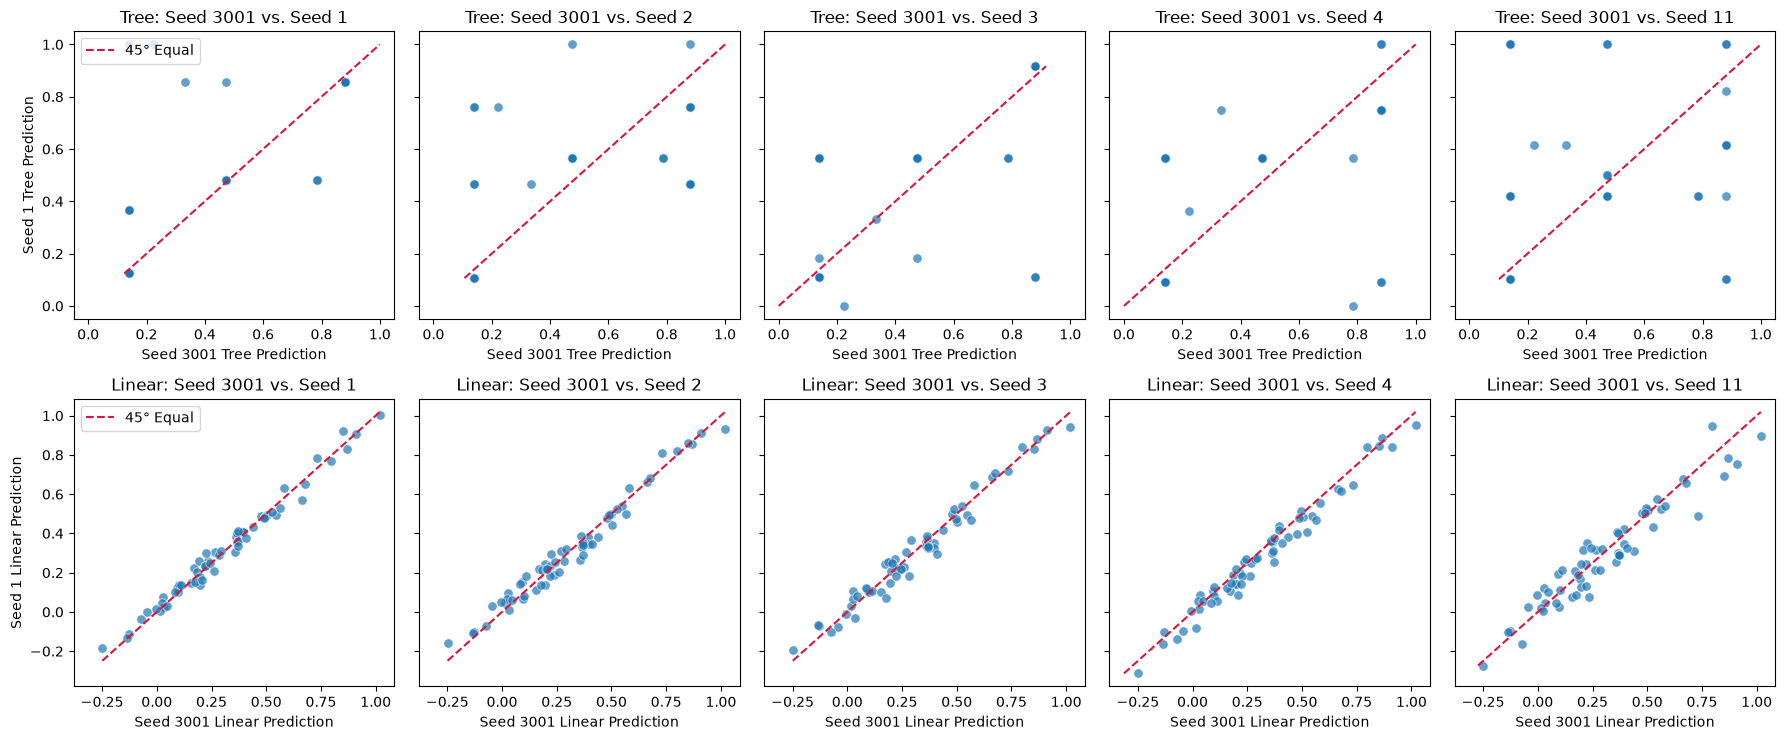

Q4b: Correlation with Question 2 Model Predictions (Seed 3001) on X_test0:


,Tree Correlation,Linear Correlation
Alternative Seed,,
1,0.8047,0.9920
2,0.7078,0.9866
3,0.7524,0.9839
4,0.6420,0.9873
11,0.5052,0.9562
Average,0.6824,0.9812


Q4c: Simple Linear Regression of Alternative Predictions on Seed 3001 Predictions:


,Tree Intercept,Tree Slope,Tree R^2,Linear Intercept,Linear Slope,Linear R^2
Alternative Seed,,,,,,
1,0.0704,0.8786,0.6475,0.0166,0.9631,0.9840
2,0.0961,0.6810,0.5010,0.0190,0.9422,0.9734
3,0.0630,0.7728,0.5661,0.0092,0.9625,0.9680
4,0.0973,0.6479,0.4121,-0.0228,0.9792,0.9748
11,0.1464,0.5582,0.2552,0.0173,0.8903,0.9143
Average,0.0946,0.7077,0.4764,0.0079,0.9475,0.9629


In [5]:
# Q4a: Scatterplots of test-set predictions from Question 2 (seed 3001) vs. alternative models
fig, axes = plt.subplots(2, len(alt_seeds), figsize=(18, 7.5), sharex='row', sharey='row')

for i, s in enumerate(alt_seeds):
    # Top row: Decision Trees
    sns.scatterplot(
        x=tree_preds[main_seed], y=tree_preds[s],
        alpha=0.7, s=45, ax=axes[0, i]
    )
    t_min = min(tree_preds[main_seed].min(), tree_preds[s].min())
    t_max = max(tree_preds[main_seed].max(), tree_preds[s].max())
    axes[0, i].plot([t_min, t_max], [t_min, t_max], color='crimson', linestyle='--', linewidth=1.5, label='45° Equal')
    axes[0, i].set(
        title=f"Tree: Seed {main_seed} vs. Seed {s}",
        xlabel=f"Seed {main_seed} Tree Prediction",
        ylabel=f"Seed {s} Tree Prediction" if i == 0 else ""
    )
    
    # Bottom row: Linear Models
    sns.scatterplot(
        x=lm_preds[main_seed], y=lm_preds[s],
        alpha=0.7, s=45, ax=axes[1, i]
    )
    l_min = min(lm_preds[main_seed].min(), lm_preds[s].min())
    l_max = max(lm_preds[main_seed].max(), lm_preds[s].max())
    axes[1, i].plot([l_min, l_max], [l_min, l_max], color='crimson', linestyle='--', linewidth=1.5, label='45° Equal')
    axes[1, i].set(
        title=f"Linear: Seed {main_seed} vs. Seed {s}",
        xlabel=f"Seed {main_seed} Linear Prediction",
        ylabel=f"Seed {s} Linear Prediction" if i == 0 else ""
    )

axes[0, 0].legend(loc='upper left')
axes[1, 0].legend(loc='upper left')
plt.tight_layout()
plt.show()

# Q4b: Correlation between Question 2 model predictions and alternative model predictions
corr_df = pd.DataFrame({
    'Tree Correlation': [tree_preds[main_seed].corr(tree_preds[s]) for s in alt_seeds],
    'Linear Correlation': [lm_preds[main_seed].corr(lm_preds[s]) for s in alt_seeds]
}, index=pd.Index(alt_seeds, name='Alternative Seed'))
corr_df.loc['Average'] = corr_df.mean()

print("Q4b: Correlation with Question 2 Model Predictions (Seed 3001) on X_test0:")
display(corr_df.round(4))

# Q4c: Simple linear regression of alternative model predictions on Question 2 predictions
# using the lecture slide inner-product formulas
def slr(x, y):
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    resid = y - (b0 + b1 * x)
    rsq = 1 - np.inner(resid, resid) / np.inner(y - y_bar, y - y_bar)
    return b0, b1, rsq

slr_rows = []
for s in alt_seeds:
    t_b0, t_b1, t_r2 = slr(tree_preds[main_seed], tree_preds[s])
    l_b0, l_b1, l_r2 = slr(lm_preds[main_seed], lm_preds[s])
    slr_rows.append({
        'Alternative Seed': s,
        'Tree Intercept': t_b0,
        'Tree Slope': t_b1,
        'Tree R^2': t_r2,
        'Linear Intercept': l_b0,
        'Linear Slope': l_b1,
        'Linear R^2': l_r2
    })

slr_df = pd.DataFrame(slr_rows).set_index('Alternative Seed')
slr_df.loc['Average'] = slr_df.mean()

print("Q4c: Simple Linear Regression of Alternative Predictions on Seed 3001 Predictions:")
display(slr_df.round(4))

Before comparing the test predictions, we can see why the linear model coefficients in Question 3 vary by different amounts across features. Raw linear slopes measure the change in predicted death risk for a 1-unit increase in a variable, so their sizes and standard deviations depend on each variable's unit scale. Platelets has a standard deviation of 97,804.24, which makes its per-unit slope and standard deviation across seeds round to 0.000000. Variables measured on small scales like transformed serum creatinine, which has a standard deviation of 0.38, and binary 0 or 1 indicators like diabetes, smoking, anaemia, and sex represent a much larger jump per unit, so their raw standard deviations across seeds are larger at 0.0152 to 0.0526. Once we multiply each slope by 1 standard deviation of its feature, the spread across seeds is small and similar for every predictor, ranging from 0.0048 to 0.0251.

To test whether the models make similar predictions, we compared all five alternative models against the seed 3001 model on the same 60 test patients from Question 2:

* **4a. Scatterplots:** The linear model predictions in the bottom row line up tightly along the 45-degree equality line in all five plots, so they appear very similar. The tree predictions in the top row slope upward in the same general direction, but the points sit in vertical and horizontal stacks because a depth-3 tree only has 7 or 8 unique leaf values. Several patients who get a predicted risk of 0.14 from the seed 3001 tree get 0.56 to 1.00 from an alternative tree, so the tree predictions are only loosely similar.
* **4b. Correlations:** The linear models are very highly correlated with the seed 3001 linear model, ranging from 0.9562 in seed 11 to 0.9920 in seed 1 with an average correlation of 0.9812. The trees have a moderate to strong positive correlation with the seed 3001 tree, ranging from 0.5052 in seed 11 up to 0.8047 in seed 1 with an average correlation of 0.6824.
* **4c. Simple linear regressions:** For the linear models, the intercepts are very close to 0 at -0.0228 to +0.0190 with an average of +0.0079, the slopes are very close to 1 at 0.8903 to 0.9792 with an average of 0.9475, and the $R^2$ values are very close to 1 at 0.9143 to 0.9840 with an average of 0.9629. For the decision trees, the intercepts are fairly close to 0 at +0.0630 to +0.1464 with an average of +0.0946, but the slopes fall well below 1 at 0.5582 to 0.8786 with an average of 0.7077, and the $R^2$ values are far from 1 at 0.2552 to 0.6475 with an average of 0.4764. Over half of the variation in an alternative tree's predictions is not explained by the Question 2 tree.

# Q5:

Linear models have very similar coefficients and nearly identical predictions across train-test splits. Ordinary least squares computes its slopes using averages across all 239 training patients at once, so swapping 20 percent of the rows barely changes the weights on major predictors like transformed serum creatinine, ejection fraction, age, and serum sodium. Their test predictions have an average correlation of 0.9812 and an average regression $R^2$ of 0.9629 across seeds.

Decision trees do not have stable structures across splits, and their predictions are only moderately similar. Because a tree picks greedy binary splits one step at a time, a small change in the training set can move the root cutoff on transformed serum creatinine or switch the root variable to ejection fraction, which changes all the branches and leaf averages below it. The trees still rely on the same main clinical risk factors, so their predictions correlate positively at an average of 0.6824, but patients near a cutoff boundary can land in a completely different leaf from one seed to the next, which brings the average prediction $R^2$ down to 0.4764.

# Q6:

This statement is **partially true in overall direction, but false if "very similar" means close agreement on individual patients** for the decision trees in this dataset.

On the true side, two trees with very different branches still split on the same core health measures: kidney function, heart pumping fraction, serum sodium, and age. Even when seed 3001 splits first on transformed serum creatinine and seed 11 splits first on ejection fraction, a patient with bad kidney numbers and low ejection fraction lands in a high-risk leaf in both trees. That shared signal keeps the tree predictions positively correlated between 0.5052 and 0.8047, with an average correlation of 0.6824, while the linear models stay above 0.9562 correlation in every split.

Calling the tree predictions "very similar" goes too far on this dataset. With only 299 patients in total and 239 in each training split, single trees have high prediction variance. Moving a few patients in or out of the training set changes the split thresholds and leaf averages enough that the simple linear regression $R^2$ between tree predictions averages just 0.4764 and drops to 0.2552 in seed 11. Individual patients can jump from a 14 percent predicted death risk in one tree to over 50 percent in another. This fragility in single trees is why we use bagging and random forests to average many trees together and stabilize the predictions.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 83e8d0ef2849a1300f1a9527ba6dd0502ef60bf5
- **AI tool and model used:** Gemini 4 Argon High Thinking

### *Prompts used

1. Can you look through my notebook and find any possible bugs/errors and verify everything is correct?
2. Can you look through my notebook and find any possible improvements to the code/logic/graphs that could be made to help clean/understand the data?

### *AI-proposed changes


1. **Q1 Imputed Lab Value Removal and Correlation Heatmap:** Drop all rows that contain the repeated mean-imputed platelet value of 263,358.03 or the repeated creatinine phosphokinase value of 582 so prior imputation does not distort the models, and add a correlation heatmap of the 11 cleaned predictors.
2. **Q2 and Q3 Cross-Validation of Tree Depth, Confusion Matrices, and Per-Seed Hyperparameter Tuning:** In Q2, check 5-fold cross-validation on the training set across tree depths 1 through 6 to justify using depth 3, display confusion matrices for the tree and linear model on the test set, and check whether the linear probability model predicts values below 0 or above 1. In Q3, run a grid search inside `fit_models` so each random seed selects its own optimal tree depth and minimum leaf size.
3. **Q4 Shared Y-Axis Label Fix, Jittered Tree Scatterplots, and Bootstrap Overlap Check:** In Q4a, fix the plotting bug where sharing the row y-axis left Seed 1 in the y-axis label for all five columns, color the points by actual death outcome, and add small random jitter to the tree scatterplots so overlapping leaf points do not hide behind one another. In Q4b and Q4c, count how many of the 60 Question 2 test patients were inside each alternative seed's training set, and run a bootstrap resample check on the Question 2 training set so the alternative models never train on the Question 2 test patients.
4. **Q5 and Q6 Patient-Level Risk Swings and Random Forest Stabilization Check:** In Q5, calculate the across-seed prediction range for each individual test patient to measure how much a single patient's predicted death risk shifts across splits. In Q6, fit a 200-tree Random Forest across the same seeds to test whether averaging many trees stabilizes the predictions on this dataset.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | Reject dropping the rows with repeated platelet or creatinine phosphokinase values because 13 patients have both values, meaning 59 unique rows or nearly 20 percent of the 299 patients would be lost, which would shrink the training splits to 191 patients and increase tree variance. Checking the outcome rate shows those 59 patients have a 37.29 percent death rate compared to 30.83 percent in the remaining 240 rows, so keeping them is reasonable. Accept updating our Q1 text from 72 rows to the exact 59 unique rows and adding the correlation heatmap. |
| 2 | Modify | Accept the Q2 additions: 5-fold cross-validation on the Question 2 training set confirms that depth 3 gets the lowest cross-validated RMSE at 0.4413 and highest R^2 at 0.1021, while depths 4 to 6 overfit with negative cross-validated R^2. Checking the linear test predictions also shows 7 of the 60 predictions fall outside 0 to 1, ranging from -0.2489 to 1.0190. Reject re-tuning tree depth and leaf size on every seed in Q3 because changing hyperparameters across splits mixes tuning differences with data instability, so keeping depth 3 fixed in Q3 is necessary for a fair comparison. |
| 3 | Accept | Fixing the y-axis label and adding color and small jitter in Q4a reveals all 60 test patients stacked on the 7 or 8 unique leaf values. Checking the split indices shows that 43 to 54 of the 60 test patients in Question 2 were inside each alternative seed's training set. Training 5 alternative models on bootstrap resamples of the Question 2 training set so none of them ever see the test patients lowers average tree correlation from 0.6824 to 0.6200 and R^2 from 0.4764 to 0.4240, while linear model correlation stays high at 0.9464 with an R^2 of 0.8976. |
| 4 | Accept | Computing the per-patient prediction range across all six seeds in Q5 shows that 12 of the 60 test patients swing by 0.50 or more across the trees with a maximum swing of 1.0000, compared to 0 patients swinging by 0.50 in the linear models where the maximum swing is 0.3195. Fitting a 200-tree depth-3 Random Forest across the same splits in Q6 raises the average prediction correlation from 0.6824 to 0.9219 and lifts the simple linear regression R^2 from 0.4764 to 0.8503. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [6]:
# Your Phase 2 solution to the problem goes here.


# Q1:

Original dataset shape: (299, 13)
Duplicate rows: 0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Missing values per column:


age_nan                         0
creatinine_phosphokinase_nan    0
ejection_fraction_nan           0
platelets_nan                   0
serum_creatinine_nan            0
serum_sodium_nan                0
time_nan                        0
anaemia_nan                     0
diabetes_nan                    0
high_blood_pressure_nan         0
sex_nan                         0
smoking_nan                     0
DEATH_EVENT_nan                 0
dtype: int64


Target variable (DEATH_EVENT) counts and death rate:
DEATH_EVENT_clean
0    203
1     96
Name: count, dtype: int64
Overall proportion of deaths: 0.3211

Cross-tabulation of DEATH_EVENT by high_blood_pressure:


high_blood_pressure_clean,0,1
DEATH_EVENT_clean,,
0,137,66
1,57,39



Median follow-up time (days) by DEATH_EVENT:
DEATH_EVENT_clean
0    172.0
1     44.5
Name: time_clean, dtype: float64
Correlation between follow-up time and DEATH_EVENT: -0.527

Most frequent values in continuous lab and age columns:
  platelets_clean: {263358.03: 25, 237000.0: 4, 228000.0: 4}
  creatinine_phosphokinase_clean: {582: 47, 129: 4, 66: 4}
  age_clean: {60.0: 33, 50.0: 27, 65.0: 26}

Unique patients with repeated platelet (263358.03) or CPK (582) values: 59 / 299
Death rate in repeated-value rows: 0.3729 vs. other rows: 0.3083


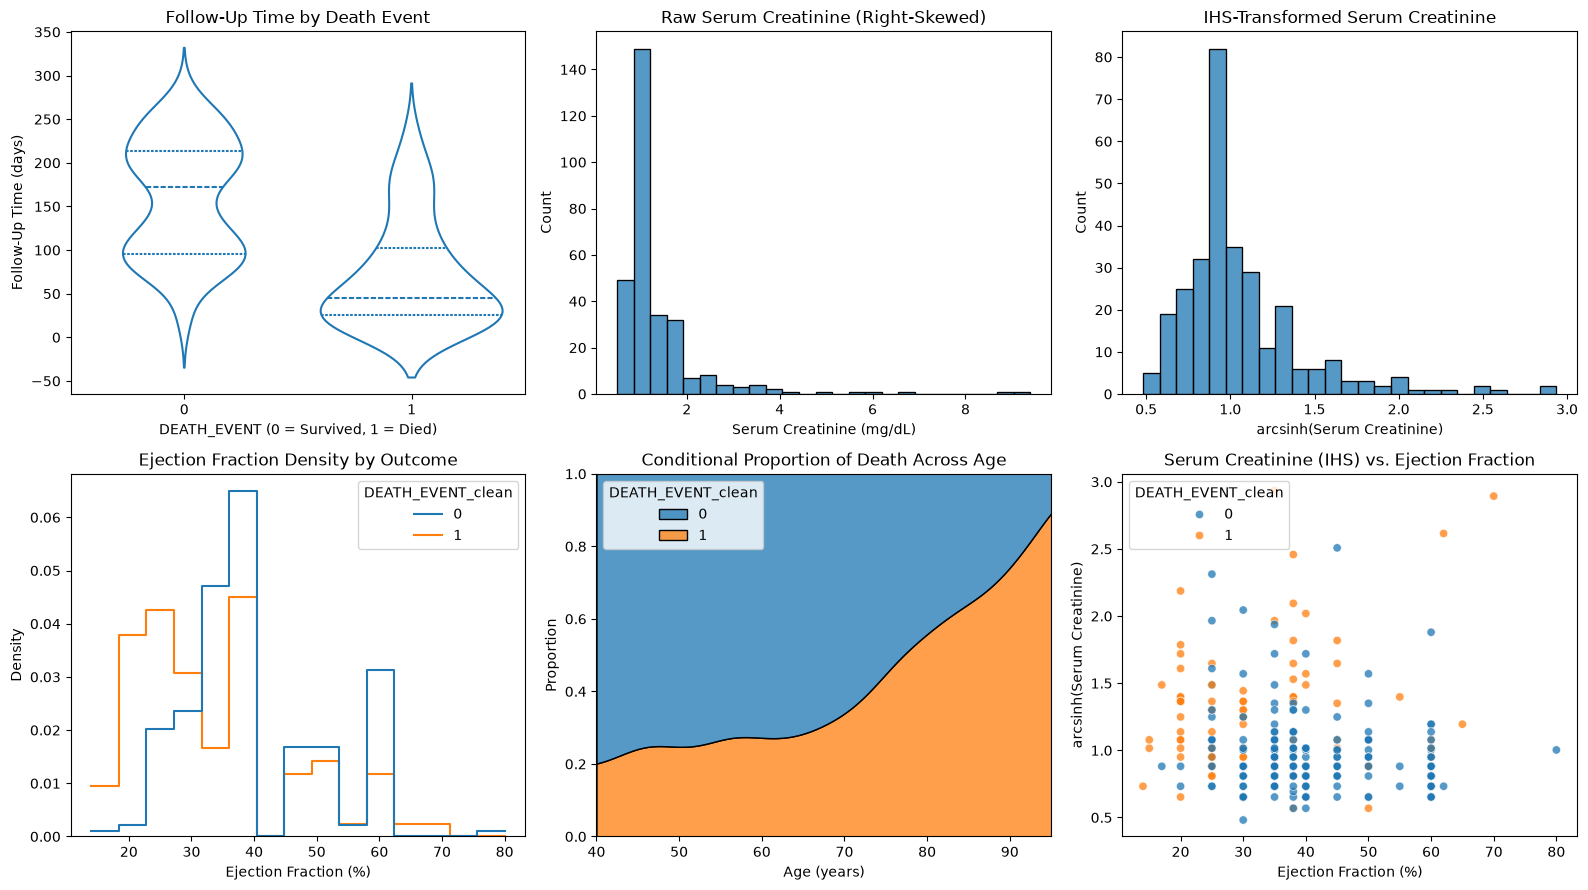


Cleaned feature matrix X shape: (299, 11)
Summary statistics of cleaned features:


,age,anaemia,creatinine_phosphokinase_ihs,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine_ihs,serum_sodium,sex,smoking
count,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00,299.00
mean,60.83,0.43,6.35,0.42,38.08,0.35,263358.03,1.05,136.63,0.65,0.32
std,11.89,0.50,1.13,0.49,11.83,0.48,97804.24,0.38,4.41,0.48,0.47
min,40.00,0.00,3.83,0.00,14.00,0.00,25100.00,0.48,113.00,0.00,0.00
25%,51.00,0.00,5.45,0.00,30.00,0.00,212500.00,0.81,134.00,0.00,0.00
50%,60.00,0.00,6.21,0.00,38.00,0.00,262000.00,0.95,137.00,1.00,0.00
75%,70.00,1.00,7.06,1.00,45.00,1.00,303500.00,1.14,140.00,1.00,1.00
max,95.00,1.00,9.66,1.00,80.00,1.00,850000.00,2.94,148.00,1.00,1.00


Correlations of cleaned features with DEATH_EVENT:


ejection_fraction              -0.2686
serum_sodium                   -0.1952
platelets                      -0.0491
smoking                        -0.0126
sex                            -0.0043
diabetes                       -0.0019
creatinine_phosphokinase_ihs    0.0321
anaemia                         0.0663
high_blood_pressure             0.0794
age                             0.2537
serum_creatinine_ihs            0.3522
dtype: float64

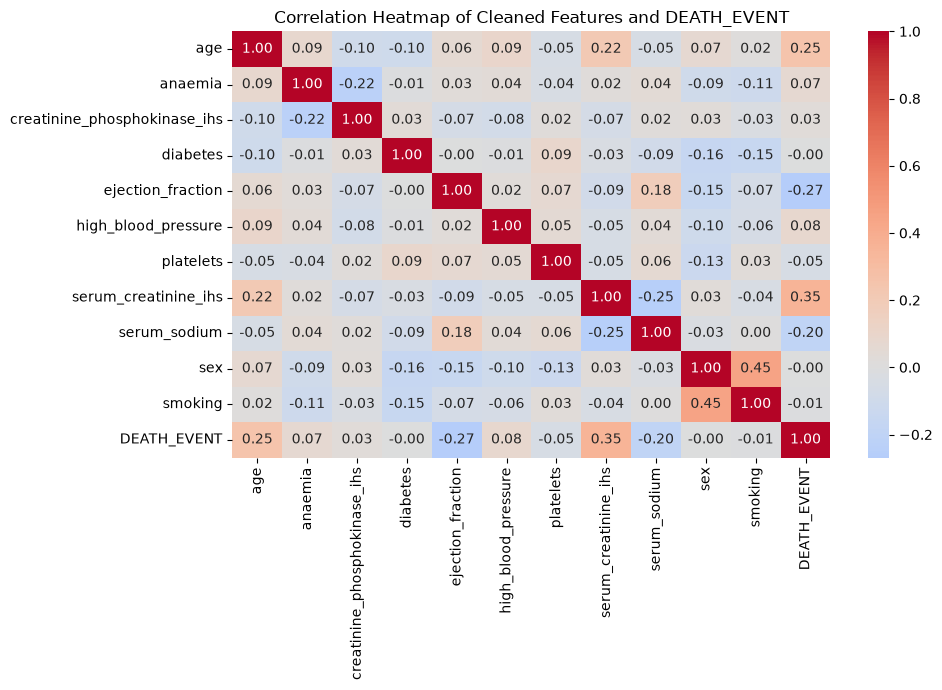

In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load the dataset (supports both repo directory structure and local folder)
if os.path.exists('data/heart_failure/heart_failure_clinical_records_dataset.csv'):
    data_path = 'data/heart_failure/heart_failure_clinical_records_dataset.csv'
elif os.path.exists('data/heart_failure.csv'):
    data_path = 'data/heart_failure.csv'
else:
    data_path = 'heart_failure_clinical_records_dataset.csv'

df = pd.read_csv(data_path)
print("Original dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
display(df.head())

# define continuous numeric columns and binary 0/1 indicator columns
num_cols = [
    'age', 'creatinine_phosphokinase', 'ejection_fraction',
    'platelets', 'serum_creatinine', 'serum_sodium', 'time'
]
bin_cols = [
    'anaemia', 'diabetes', 'high_blood_pressure',
    'sex', 'smoking', 'DEATH_EVENT'
]

# coerce variables to numeric and track missingness with _nan indicator columns
for col in num_cols + bin_cols:
    df[f'{col}_clean'] = pd.to_numeric(df[col], errors='coerce')
    df[f'{col}_nan'] = df[f'{col}_clean'].isnull()

print("\nMissing values per column:")
display(df[[f'{c}_nan' for c in num_cols + bin_cols]].sum())

# inspect the target variable distribution and cross-tabulations
print("\nTarget variable (DEATH_EVENT) counts and death rate:")
print(df['DEATH_EVENT_clean'].value_counts())
print("Overall proportion of deaths:", round(df['DEATH_EVENT_clean'].mean(), 4))

print("\nCross-tabulation of DEATH_EVENT by high_blood_pressure:")
display(pd.crosstab(df['DEATH_EVENT_clean'], df['high_blood_pressure_clean']))

# inspect follow-up time by outcome to check for target leakage
print("\nMedian follow-up time (days) by DEATH_EVENT:")
print(df.groupby('DEATH_EVENT_clean')['time_clean'].median())
print("Correlation between follow-up time and DEATH_EVENT:", round(df['time_clean'].corr(df['DEATH_EVENT_clean']), 4))

# check frequent repeated values that reflect prior mean imputation in the raw data
print("\nMost frequent values in continuous lab and age columns:")
for col in ['platelets_clean', 'creatinine_phosphokinase_clean', 'age_clean']:
    print(f"  {col}: {df[col].value_counts().head(3).to_dict()}")

# PHASE 2 IMPROVEMENT 1a: Check exact unique row count and death rate for repeated platelet/CPK rows
imputed_mask = (df['platelets_clean'] == 263358.03) | (df['creatinine_phosphokinase_clean'] == 582)
print(f"\nUnique patients with repeated platelet (263358.03) or CPK (582) values: {imputed_mask.sum()} / {len(df)}")
print(f"Death rate in repeated-value rows: {df.loc[imputed_mask, 'DEATH_EVENT_clean'].mean():.4f} vs. other rows: {df.loc[~imputed_mask, 'DEATH_EVENT_clean'].mean():.4f}")

# apply inverse hyperbolic sine (arcsinh) transformation to heavily right-skewed lab variables
df['creatinine_phosphokinase_ihs'] = np.arcsinh(df['creatinine_phosphokinase_clean'])
df['serum_creatinine_ihs'] = np.arcsinh(df['serum_creatinine_clean'])

# EDA visualizations using course slide plot types
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

sns.violinplot(data=df, x='DEATH_EVENT_clean', y='time_clean', inner='quart', fill=False, ax=axes[0, 0])
axes[0, 0].set(
    title='Follow-Up Time by Death Event',
    xlabel='DEATH_EVENT (0 = Survived, 1 = Died)',
    ylabel='Follow-Up Time (days)'
)

sns.histplot(data=df, x='serum_creatinine_clean', bins=25, ax=axes[0, 1])
axes[0, 1].set(
    title='Raw Serum Creatinine (Right-Skewed)',
    xlabel='Serum Creatinine (mg/dL)',
    ylabel='Count'
)

sns.histplot(data=df, x='serum_creatinine_ihs', bins=25, ax=axes[0, 2])
axes[0, 2].set(
    title='IHS-Transformed Serum Creatinine',
    xlabel='arcsinh(Serum Creatinine)',
    ylabel='Count'
)

sns.histplot(
    data=df, x='ejection_fraction_clean', hue='DEATH_EVENT_clean',
    stat='density', common_norm=False, multiple='layer', element='step', fill=False, ax=axes[1, 0]
)
axes[1, 0].set(
    title='Ejection Fraction Density by Outcome',
    xlabel='Ejection Fraction (%)',
    ylabel='Density'
)

sns.kdeplot(data=df, x='age_clean', hue='DEATH_EVENT_clean', multiple='fill', cut=0, ax=axes[1, 1])
axes[1, 1].set(
    title='Conditional Proportion of Death Across Age',
    xlabel='Age (years)',
    ylabel='Proportion'
)

sns.scatterplot(
    data=df, x='ejection_fraction_clean', y='serum_creatinine_ihs',
    hue='DEATH_EVENT_clean', alpha=0.75, ax=axes[1, 2]
)
axes[1, 2].set(
    title='Serum Creatinine (IHS) vs. Ejection Fraction',
    xlabel='Ejection Fraction (%)',
    ylabel='arcsinh(Serum Creatinine)'
)

plt.tight_layout()
plt.show()

# construct the cleaned feature matrix X (dropping time due to outcome leakage) and target y
clean_feature_Map = {
    'age_clean': 'age',
    'anaemia_clean': 'anaemia',
    'creatinine_phosphokinase_ihs': 'creatinine_phosphokinase_ihs',
    'diabetes_clean': 'diabetes',
    'ejection_fraction_clean': 'ejection_fraction',
    'high_blood_pressure_clean': 'high_blood_pressure',
    'platelets_clean': 'platelets',
    'serum_creatinine_ihs': 'serum_creatinine_ihs',
    'serum_sodium_clean': 'serum_sodium',
    'sex_clean': 'sex',
    'smoking_clean': 'smoking'
}

X = df[list(clean_feature_Map.keys())].rename(columns=clean_feature_Map).copy()
y = df['DEATH_EVENT_clean'].copy()
features = list(X.columns)

print(f"\nCleaned feature matrix X shape: {X.shape}")
print("Summary statistics of cleaned features:")
display(X.describe().round(2))

print("Correlations of cleaned features with DEATH_EVENT:")
display(X.apply(lambda s: s.corr(y)).sort_values().round(4))

# PHASE 2 IMPROVEMENT 1b: Correlation heatmap of cleaned predictors and DEATH_EVENT
plt.figure(figsize=(10, 7))
corr_matrix = X.assign(DEATH_EVENT=y).corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Cleaned Features and DEATH_EVENT')
plt.tight_layout()
plt.show()

The raw heart failure dataset has 299 patients and 13 columns with no missing values and no duplicate rows. The outcome variable equals 1 for the 96 patients who died during the study and 0 for the 203 patients who survived, which gives a death rate of 32.11 percent. Five features are already 0 and 1 indicators for anaemia, diabetes, high blood pressure, sex, and smoking, so they do not need any extra encoding.

We made three main decisions while cleaning the numeric variables. First, we dropped follow-up time because it measures days until a patient dies or leaves the study. Patients who died had a median follow-up of 44.5 days compared to 172.0 days for survivors, giving a correlation of -0.5270 with death. A doctor cannot know follow-up length at the start of care, so keeping time would leak the answer into the models. Second, we applied the inverse hyperbolic sine transform to creatinine phosphokinase and serum creatinine. Both lab values have heavy right tails, with creatinine phosphokinase reaching up to 7,861 against a median of 250.0 and serum creatinine reaching 9.4 against a median of 1.10. Transforming them keeps extreme outliers from pulling on the linear model slopes. Third, we checked repeated numbers in the continuous columns. A platelet count of 263,358.03 shows up 25 times and equals the exact column mean, while a creatinine phosphokinase value of 582 shows up 47 times. Because 13 patients share both values, 59 unique patients have at least one of these filled-in numbers. Their death rate is 37.29 percent compared to 30.83 percent for the other 240 patients, so we kept those rows rather than losing nearly 20 percent of our sample.

Across the 11 cleaned features, transformed serum creatinine has the strongest positive correlation with death at 0.3522, followed by age at 0.2537. Ejection fraction has the strongest negative correlation at -0.2686, followed by serum sodium at -0.1952.

# Q2:

Training set shape: X_train0 = (239, 11), y_train0 = (239,)
Test set shape:     X_test0  = (60, 11),  y_test0  = (60,)

5-Fold Cross-Validation on X_train0 Across Tree Depths 1 to 6:


,Leaves,Train RMSE,5-Fold CV RMSE,5-Fold CV R^2
max_depth,,,,
1,2,0.4404,0.4629,0.0078
2,4,0.4111,0.4658,-0.0031
3,8,0.3710,0.4413,0.1021
4,15,0.3327,0.4686,-0.0178
5,21,0.3092,0.5132,-0.2156
6,28,0.2755,0.5353,-0.3237



Question 2 Model Performance (Seed 3001):


,Model,Seed,Train RMSE,Test RMSE,Train R^2,Test R^2,Test Accuracy (p > 0.5)
0,Decision Tree (max_depth=3),3001,0.3710,0.4053,0.3820,0.1601,0.7500
1,Linear Regression (OLS),3001,0.4096,0.3959,0.2467,0.1985,0.7833



Decision Tree Test Confusion Matrix (cutoff = 0.5):


Predicted,0,1
Actual,,
0,39,5
1,10,6


Linear Model Test Confusion Matrix (cutoff = 0.5):


Predicted,0,1
Actual,,
0,39,5
1,8,8


Linear model test prediction range: [-0.2489, 1.0190] (6 below 0, 1 above 1)


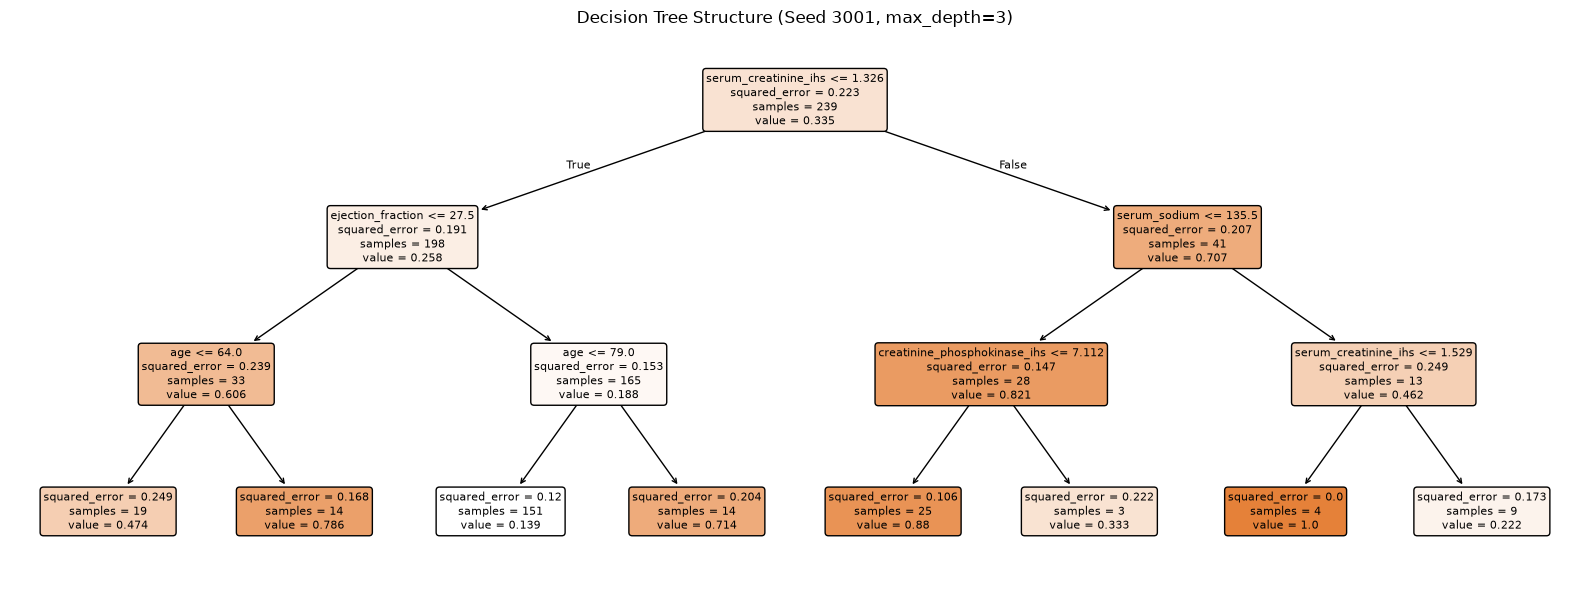

Text representation of the Question 2 Decision Tree:
|--- serum_creatinine_ihs <= 1.33
|   |--- ejection_fraction <= 27.50
|   |   |--- age <= 64.00
|   |   |   |--- value: [0.47]
|   |   |--- age >  64.00
|   |   |   |--- value: [0.79]
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.00
|   |   |   |--- value: [0.14]
|   |   |--- age >  79.00
|   |   |   |--- value: [0.71]
|--- serum_creatinine_ihs >  1.33
|   |--- serum_sodium <= 135.50
|   |   |--- creatinine_phosphokinase_ihs <= 7.11
|   |   |   |--- value: [0.88]
|   |   |--- creatinine_phosphokinase_ihs >  7.11
|   |   |   |--- value: [0.33]
|   |--- serum_sodium >  135.50
|   |   |--- serum_creatinine_ihs <= 1.53
|   |   |   |--- value: [1.00]
|   |   |--- serum_creatinine_ihs >  1.53
|   |   |   |--- value: [0.22]

Question 2 Linear Model Coefficients (Seed 3001):


sex                            -0.081955
serum_sodium                   -0.009998
ejection_fraction              -0.009760
platelets                      -0.000000
age                             0.008769
smoking                         0.029586
creatinine_phosphokinase_ihs    0.034670
anaemia                         0.046802
diabetes                        0.056883
high_blood_pressure             0.095363
serum_creatinine_ihs            0.346771
dtype: float64

In [8]:
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score, accuracy_score

# helper function to split data for a given seed and fit both a tree and a linear model
def fit_models(seed):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=seed
    )
    tree = DecisionTreeRegressor(max_depth=3, random_state=100).fit(X_train, y_train)
    lm = LinearRegression().fit(X_train, y_train)
    return tree, lm, X_train, X_test, y_train, y_test

# perform 80/20 train-test split and fit models for our primary seed
main_seed = 3001
tree0, lm0, X_train0, X_test0, y_train0, y_test0 = fit_models(main_seed)

print(f"Training set shape: X_train0 = {X_train0.shape}, y_train0 = {y_train0.shape}")
print(f"Test set shape:     X_test0  = {X_test0.shape},  y_test0  = {y_test0.shape}")

# PHASE 2 IMPROVEMENT 2a: Use 5-fold CV on X_train0 to verify that max_depth=3 is optimal
kf = KFold(n_splits=5, shuffle=True, random_state=100)
cv_depth_rows = []
for d in range(1, 7):
    dt_cv = DecisionTreeRegressor(max_depth=d, random_state=100)
    cv_rmse = -cross_val_score(dt_cv, X_train0, y_train0, cv=kf, scoring='neg_root_mean_squared_error').mean()
    cv_r2 = cross_val_score(dt_cv, X_train0, y_train0, cv=kf, scoring='r2').mean()
    dt_cv.fit(X_train0, y_train0)
    cv_depth_rows.append({
        'max_depth': d,
        'Leaves': dt_cv.get_n_leaves(),
        'Train RMSE': root_mean_squared_error(y_train0, dt_cv.predict(X_train0)),
        '5-Fold CV RMSE': cv_rmse,
        '5-Fold CV R^2': cv_r2
    })
print("\n5-Fold Cross-Validation on X_train0 Across Tree Depths 1 to 6:")
display(pd.DataFrame(cv_depth_rows).set_index('max_depth').round(4))

# set aside test-set predictions from the Question 2 models
tree_pred0 = tree0.predict(X_test0)
lm_pred0 = lm0.predict(X_test0)

# evaluate performance on both training and test sets
q2_results = pd.DataFrame([
    {
        'Model': 'Decision Tree (max_depth=3)',
        'Seed': main_seed,
        'Train RMSE': root_mean_squared_error(y_train0, tree0.predict(X_train0)),
        'Test RMSE': root_mean_squared_error(y_test0, tree_pred0),
        'Train R^2': r2_score(y_train0, tree0.predict(X_train0)),
        'Test R^2': r2_score(y_test0, tree_pred0),
        'Test Accuracy (p > 0.5)': accuracy_score(y_test0, tree_pred0 > 0.5)
    },
    {
        'Model': 'Linear Regression (OLS)',
        'Seed': main_seed,
        'Train RMSE': root_mean_squared_error(y_train0, lm0.predict(X_train0)),
        'Test RMSE': root_mean_squared_error(y_test0, lm_pred0),
        'Train R^2': r2_score(y_train0, lm0.predict(X_train0)),
        'Test R^2': r2_score(y_test0, lm_pred0),
        'Test Accuracy (p > 0.5)': accuracy_score(y_test0, lm_pred0 > 0.5)
    }
])

print("\nQuestion 2 Model Performance (Seed 3001):")
display(q2_results.round(4))

# PHASE 2 IMPROVEMENT 2b: Confusion matrices and check for out-of-bounds linear probability predictions
print("\nDecision Tree Test Confusion Matrix (cutoff = 0.5):")
display(pd.crosstab(y_test0, (tree_pred0 > 0.5).astype(int), rownames=['Actual'], colnames=['Predicted']))

print("Linear Model Test Confusion Matrix (cutoff = 0.5):")
display(pd.crosstab(y_test0, (lm_pred0 > 0.5).astype(int), rownames=['Actual'], colnames=['Predicted']))

out_low = int((lm_pred0 < 0).sum())
out_high = int((lm_pred0 > 1).sum())
print(f"Linear model test prediction range: [{lm_pred0.min():.4f}, {lm_pred0.max():.4f}] ({out_low} below 0, {out_high} above 1)")

# visualize the fitted Question 2 Decision Tree
plt.figure(figsize=(16, 6))
plot_tree(
    tree0, feature_names=features, filled=True,
    rounded=True, impurity=True, fontsize=8
)
plt.title(f"Decision Tree Structure (Seed {main_seed}, max_depth=3)")
plt.tight_layout()
plt.show()

print("Text representation of the Question 2 Decision Tree:")
print(export_text(tree0, feature_names=features))

print("Question 2 Linear Model Coefficients (Seed 3001):")
coef0_series = pd.Series(lm0.coef_, index=features).sort_values()
display(coef0_series.round(6))

We split the cleaned data 80/20 using seed 3001, which put 239 patients in the training set and 60 patients in the test set. Checking 5-fold cross-validation on the 239 training patients across tree depths 1 through 6 confirms that depth 3 gets the lowest cross-validated RMSE at 0.4413 and highest cross-validated $R^2$ at 0.1021, whereas depths 4, 5, and 6 overfit the small training sample and get negative cross-validated $R^2$ values.

The depth-3 regression tree predicts the average death rate in each leaf. It gets a training RMSE of 0.3710 and a training $R^2$ of 0.3820. On the test set, it gets a test RMSE of 0.4053, a test $R^2$ of 0.1601, and an accuracy of 0.7500 at a 0.5 cutoff, correctly classifying 39 of 44 survivors and 6 of 16 deaths. The tree splits first on transformed serum creatinine at 1.326, then splits on ejection fraction at 27.50 on the left branch and serum sodium at 135.50 on the right branch, finishing with 8 leaves.

The linear model gets a worse training fit with a training RMSE of 0.4096 and a training $R^2$ of 0.2467, but it beats the tree on the held-out test set with a test RMSE of 0.3959, a test $R^2$ of 0.1985, and a test accuracy of 0.7833, correctly classifying 39 of 44 survivors and 8 of 16 deaths. Unlike the tree, whose leaf averages always stay between 0 and 1, the linear probability model produces 7 test predictions outside 0 to 1, with 6 below 0 down to -0.2489 and 1 above 1 at 1.0190. Its largest positive weights are on transformed serum creatinine at +0.3468, high blood pressure at +0.0954, diabetes at +0.0569, and anaemia at +0.0468, along with +0.0088 per year of age. Its negative weights are on sex at -0.0820, serum sodium at -0.0100, and ejection fraction at -0.0098.

# Q3:

Test Set Performance Across All 6 Seeds (Evaluated on Each Seed's Own Test Set):


,Tree Test RMSE,Tree Test R^2,Tree Test Acc,Linear Test RMSE,Linear Test R^2,Linear Test Acc
Seed,,,,,,
3001,0.4053,0.1601,0.7500,0.3959,0.1985,0.7833
1,0.3839,0.1762,0.7667,0.3813,0.1871,0.8167
2,0.4123,0.1628,0.7500,0.3936,0.2370,0.7833
3,0.4126,0.2341,0.7667,0.4315,0.1620,0.6833
4,0.4319,0.1119,0.7167,0.4358,0.0956,0.7333
11,0.4285,0.0958,0.8000,0.4276,0.0995,0.7167



Structural Summary of Fitted Decision Trees Across Seeds:


,Root Split,Left Child Split (Level 2),Right Child Split (Level 2),Leaves,Features Used
Seed,,,,,
3001,serum_creatinine_ihs <= 1.326,ejection_fraction <= 27.500,serum_sodium <= 135.500,8,5
1,serum_creatinine_ihs <= 1.166,ejection_fraction <= 27.500,serum_sodium <= 135.500,8,4
2,serum_creatinine_ihs <= 1.166,ejection_fraction <= 27.500,ejection_fraction <= 22.500,7,5
3,serum_creatinine_ihs <= 1.358,ejection_fraction <= 32.500,serum_sodium <= 135.500,8,6
4,serum_creatinine_ihs <= 1.358,ejection_fraction <= 32.500,serum_creatinine_ihs <= 1.466,7,4
11,ejection_fraction <= 32.500,ejection_fraction <= 22.500,age <= 79.500,8,4


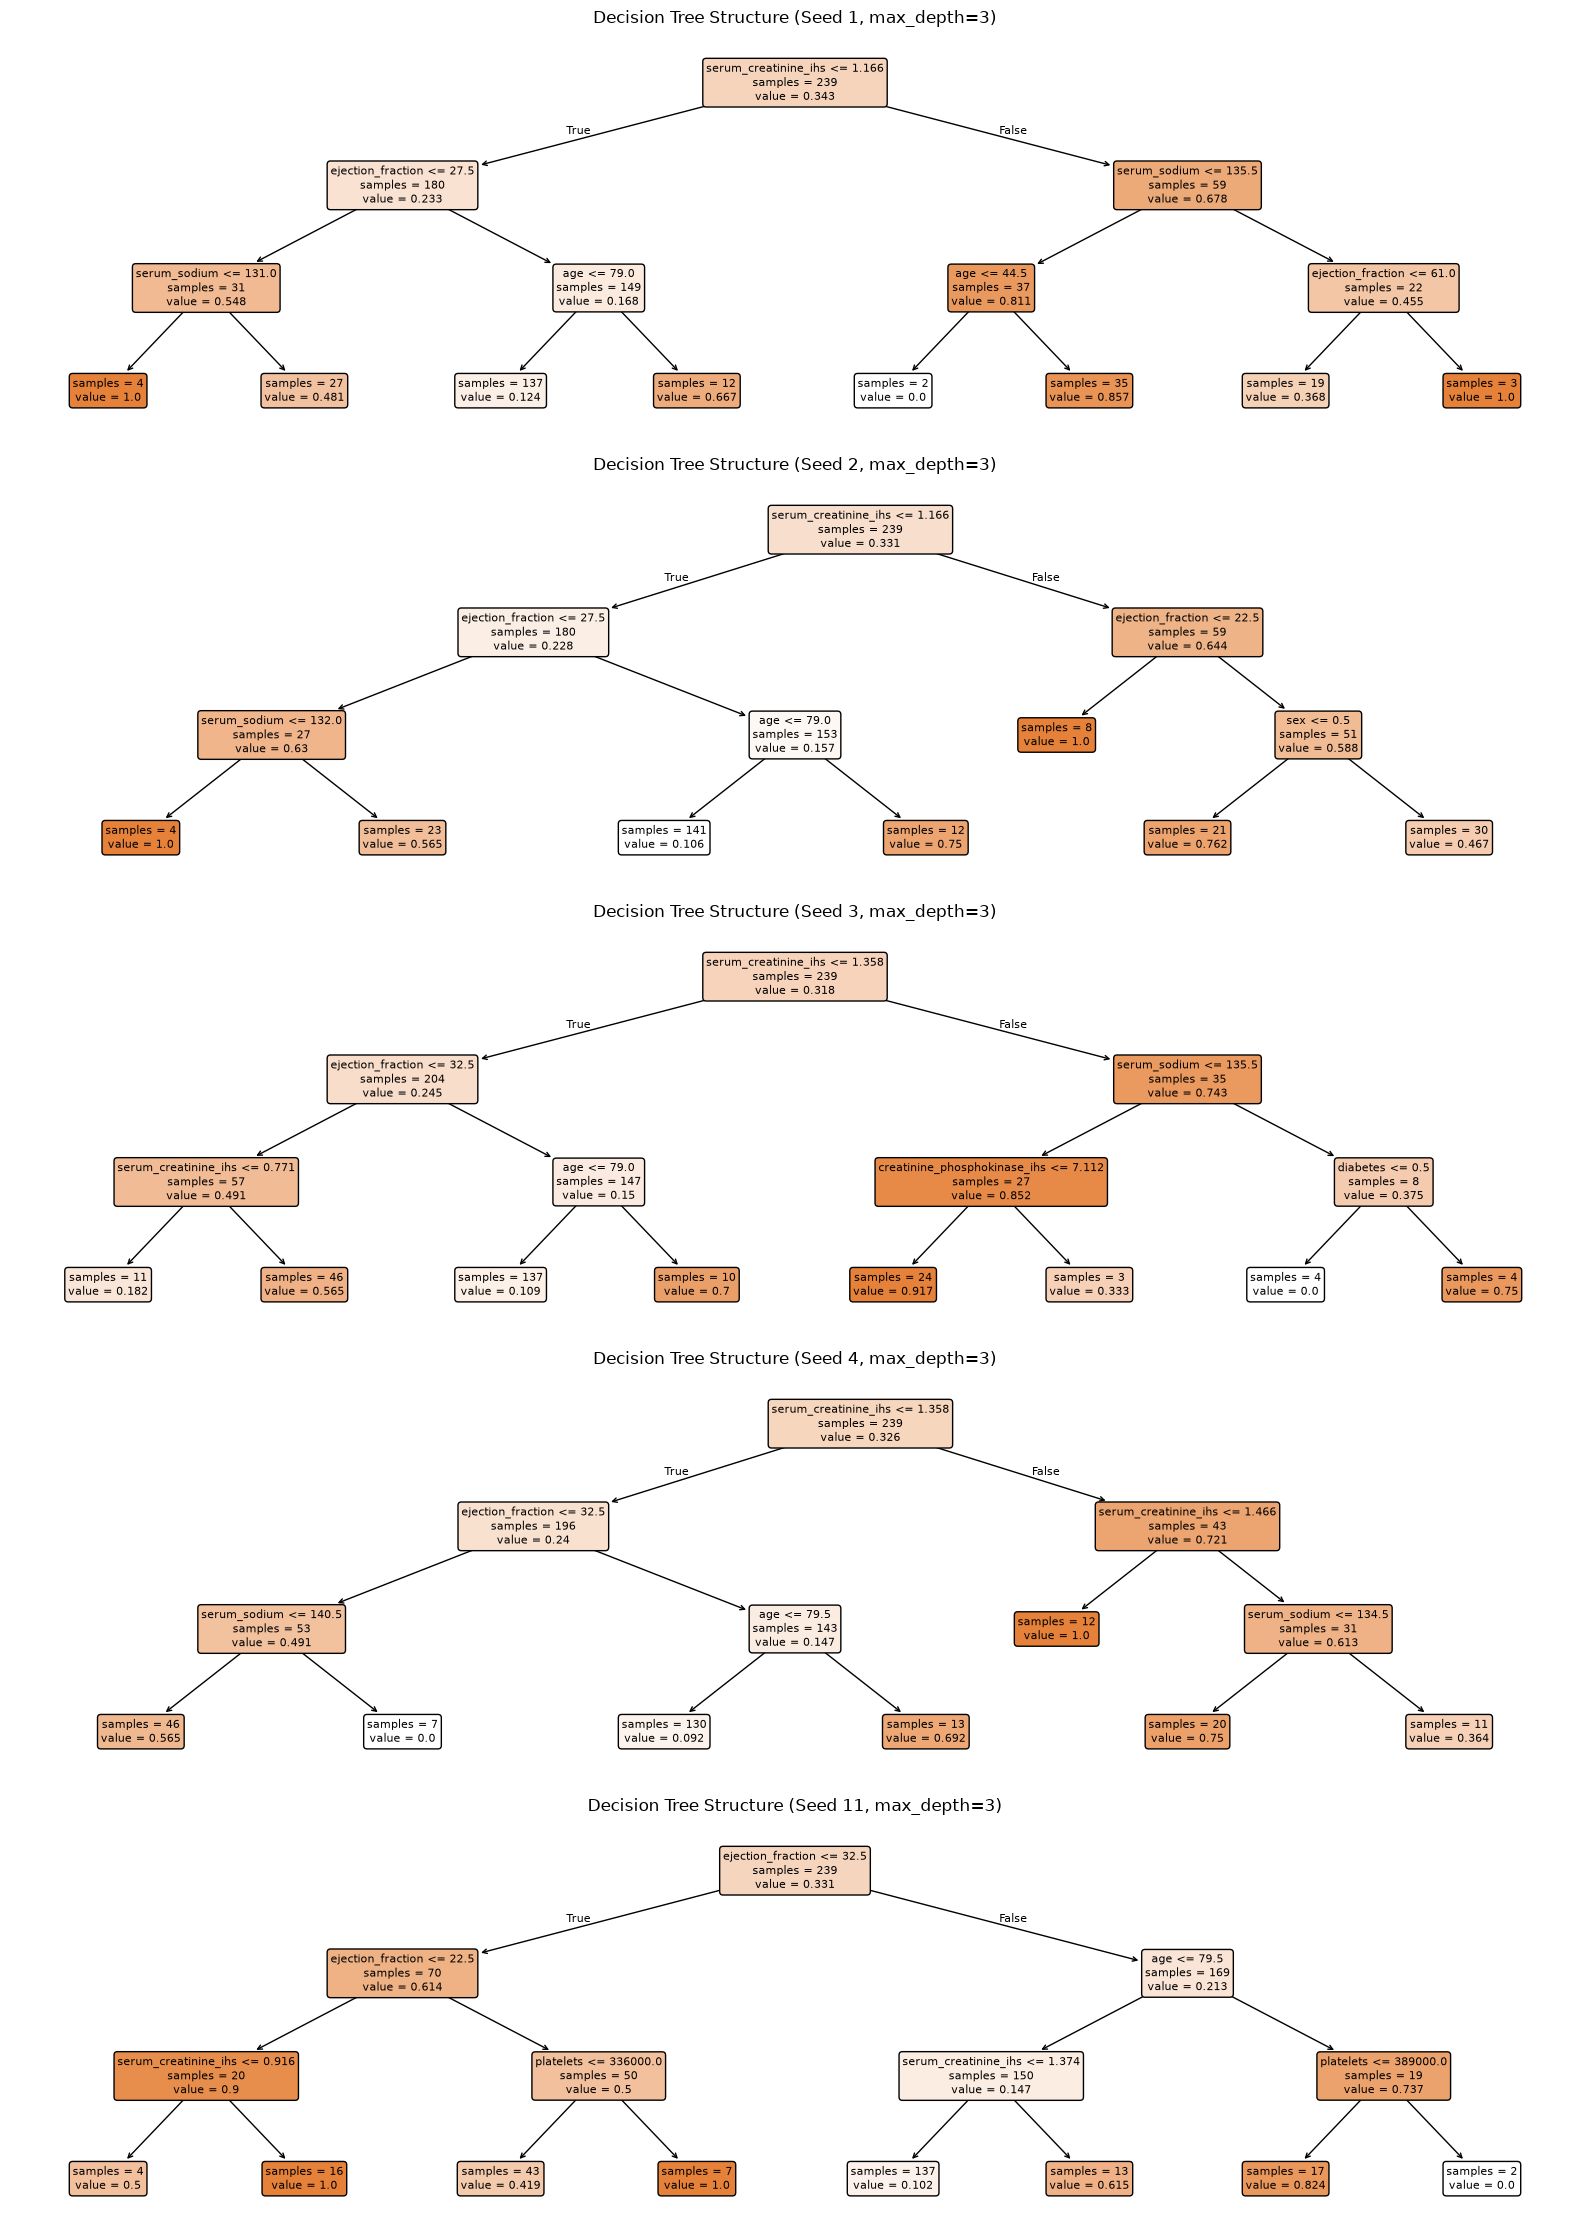

Linear Model Coefficients Across All 6 Seeds:


,3001,1,2,3,4,11,Mean,Std Dev,Min,Max
age,0.008769,0.007318,0.007757,0.008608,0.009696,0.009094,0.008540,0.000873,0.007318,0.009696
anaemia,0.046802,0.061603,0.066428,0.000562,0.059946,0.093806,0.054858,0.030774,0.000562,0.093806
creatinine_phosphokinase_ihs,0.034670,0.040025,0.039012,0.042694,0.020466,0.043705,0.036762,0.008591,0.020466,0.043705
diabetes,0.056883,0.050603,-0.013651,-0.006983,0.072416,-0.057871,0.016899,0.050815,-0.057871,0.072416
ejection_fraction,-0.009760,-0.008927,-0.008750,-0.009281,-0.009076,-0.010673,-0.009411,0.000709,-0.010673,-0.008750
high_blood_pressure,0.095363,0.051563,0.061679,0.080722,0.072960,0.074593,0.072813,0.015164,0.051563,0.095363
platelets,-0.000000,-0.000000,-0.000000,0.000000,-0.000000,0.000000,-0.000000,0.000000,-0.000000,0.000000
serum_creatinine_ihs,0.346771,0.361715,0.359247,0.357377,0.341793,0.225822,0.332121,0.052644,0.225822,0.361715
serum_sodium,-0.009998,-0.009783,-0.007347,-0.010122,-0.008513,-0.009678,-0.009240,0.001091,-0.010122,-0.007347
sex,-0.081955,-0.056883,-0.069931,-0.051181,-0.017093,-0.005283,-0.047054,0.029992,-0.081955,-0.005283


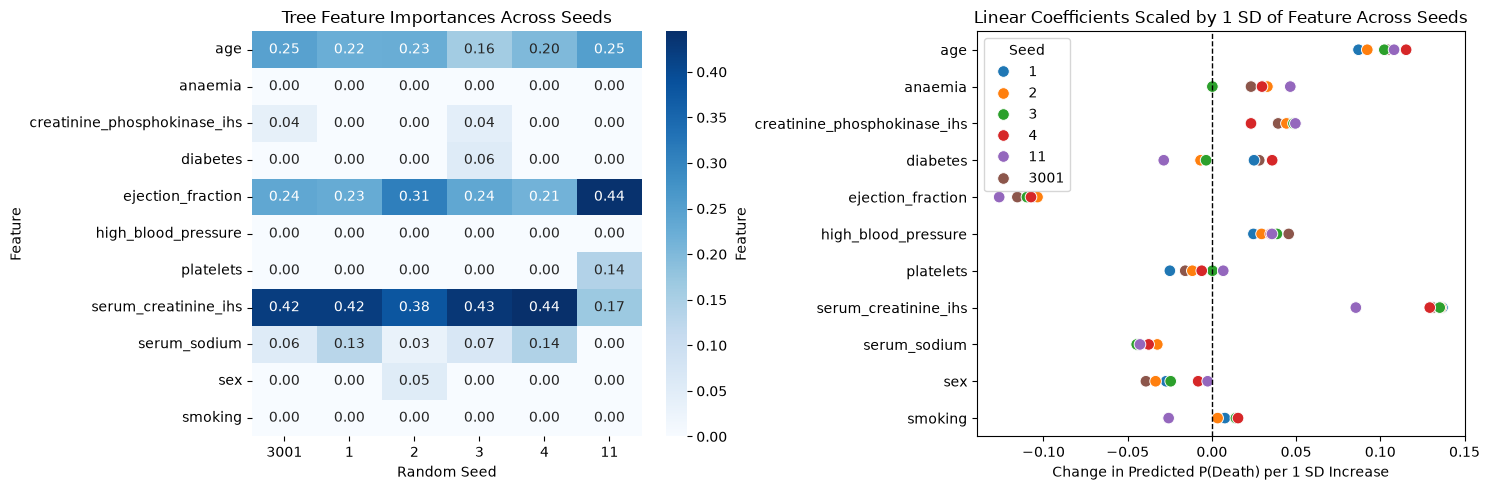

In [9]:
# repeat Step 2 across 5 different saved random seeds
alt_seeds = [1, 2, 3, 4, 11]
all_seeds = [main_seed] + alt_seeds

# store predictions on the Question 2 test set (X_test0), coefficients, and tree summaries
tree_preds = pd.DataFrame({main_seed: tree_pred0}, index=X_test0.index)
lm_preds = pd.DataFrame({main_seed: lm_pred0}, index=X_test0.index)
coefs_df = pd.DataFrame({main_seed: lm0.coef_}, index=features)
importances_df = pd.DataFrame({main_seed: tree0.feature_importances_}, index=features)

seed_perf_rows = []
tree_summary_rows = []
fitted_trees = {main_seed: tree0}

for s in all_seeds:
    tree_s, lm_s, X_tr_s, X_te_s, y_tr_s, y_te_s = fit_models(s)
    fitted_trees[s] = tree_s
    
    # predictions on each seed's own test split to evaluate test performance
    t_own_pred = tree_s.predict(X_te_s)
    l_own_pred = lm_s.predict(X_te_s)
    
    seed_perf_rows.append({
        'Seed': s,
        'Tree Test RMSE': root_mean_squared_error(y_te_s, t_own_pred),
        'Tree Test R^2': r2_score(y_te_s, t_own_pred),
        'Tree Test Acc': accuracy_score(y_te_s, t_own_pred > 0.5),
        'Linear Test RMSE': root_mean_squared_error(y_te_s, l_own_pred),
        'Linear Test R^2': r2_score(y_te_s, l_own_pred),
        'Linear Test Acc': accuracy_score(y_te_s, l_own_pred > 0.5)
    })
    
    # set aside predictions on the Question 2 test set (X_test0) for Question 4 comparisons
    if s != main_seed:
        tree_preds[s] = tree_s.predict(X_test0)
        lm_preds[s] = lm_s.predict(X_test0)
        coefs_df[s] = lm_s.coef_
        importances_df[s] = tree_s.feature_importances_
    
    # extract root split, level-2 splits, level-3 splits, and leaf count for each tree
    t_struct = tree_s.tree_
    root_feat = features[t_struct.feature[0]]
    root_thr = t_struct.threshold[0]
    left_idx, right_idx = t_struct.children_left[0], t_struct.children_right[0]
    left_feat = features[t_struct.feature[left_idx]] if t_struct.feature[left_idx] >= 0 else 'leaf'
    right_feat = features[t_struct.feature[right_idx]] if t_struct.feature[right_idx] >= 0 else 'leaf'
    
    tree_summary_rows.append({
        'Seed': s,
        'Root Split': f"{root_feat} <= {root_thr:.3f}",
        'Left Child Split (Level 2)': f"{left_feat} <= {t_struct.threshold[left_idx]:.3f}",
        'Right Child Split (Level 2)': f"{right_feat} <= {t_struct.threshold[right_idx]:.3f}",
        'Leaves': tree_s.get_n_leaves(),
        'Features Used': int((tree_s.feature_importances_ > 0).sum())
    })

print("Test Set Performance Across All 6 Seeds (Evaluated on Each Seed's Own Test Set):")
display(pd.DataFrame(seed_perf_rows).set_index('Seed').round(4))

print("\nStructural Summary of Fitted Decision Trees Across Seeds:")
display(pd.DataFrame(tree_summary_rows).set_index('Seed'))

# plot the 5 alternative trees to compare their visual structure
fig, axes = plt.subplots(len(alt_seeds), 1, figsize=(16, 4.5 * len(alt_seeds)))
for ax, s in zip(axes, alt_seeds):
    plot_tree(
        fitted_trees[s], feature_names=features, filled=True,
        rounded=True, impurity=False, fontsize=8, ax=ax
    )
    ax.set_title(f"Decision Tree Structure (Seed {s}, max_depth=3)")
plt.tight_layout()
plt.show()

# summarize linear model coefficients across all seeds
coefs_summary = coefs_df.copy()
coefs_summary['Mean'] = coefs_df.mean(axis=1)
coefs_summary['Std Dev'] = coefs_df.std(axis=1)
coefs_summary['Min'] = coefs_df.min(axis=1)
coefs_summary['Max'] = coefs_df.max(axis=1)

print("Linear Model Coefficients Across All 6 Seeds:")
display(coefs_summary.round(6))

# compare standardized linear model coefficients (coef * feature std) and tree importances
scaled_coefs_df = coefs_df.multiply(X.std(axis=0), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(importances_df, annot=True, fmt='.2f', cmap='Blues', ax=axes[0])
axes[0].set(
    title='Tree Feature Importances Across Seeds',
    xlabel='Random Seed',
    ylabel='Feature'
)

coef_long = scaled_coefs_df.reset_index().melt(id_vars='index', var_name='Seed', value_name='Std_Coef')
sns.scatterplot(data=coef_long, x='Std_Coef', y='index', hue='Seed', palette='tab10', s=70, ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set(
    title='Linear Coefficients Scaled by 1 SD of Feature Across Seeds',
    xlabel='Change in Predicted P(Death) per 1 SD Increase',
    ylabel='Feature'
)

plt.tight_layout()
plt.show()

We ran the same 80/20 split and model fitting for five more saved seeds: 1, 2, 3, 4, and 11, and saved every model's predictions on the Question 2 test set.

The decision trees change a lot from split to split. Five of the six trees use transformed serum creatinine at the root node, but the cutoff shifts between 1.326, 1.166, and 1.358. Seed 11 drops serum creatinine from the root altogether and splits first on ejection fraction at 32.500. The second level changes even more. On the left branch, ejection fraction uses a cutoff of 27.500 in seeds 3001, 1, and 2, moves to 32.500 in seeds 3 and 4, and drops to 22.500 in seed 11. On the right branch, seeds 3001, 1, and 3 split on serum sodium at 135.500, seed 2 splits on ejection fraction at 22.500, seed 4 splits on transformed serum creatinine at 1.466, and seed 11 splits on age at 79.500. Deeper in the tree, features like platelets, transformed creatinine phosphokinase, diabetes, and sex show up in one or two seeds and disappear in the rest. Feature importance scores jump around as well, with transformed serum creatinine dropping from 0.44 in seed 4 down to 0.17 in seed 11 while ejection fraction jumps from 0.21 to 0.44.

The linear model coefficients stay much closer together across all six seeds. The main continuous variables keep the same sign and similar size every time. Transformed serum creatinine has a mean slope of +0.3321 with a standard deviation of 0.0526, ejection fraction has a mean of -0.0094 with a standard deviation of 0.0007, age has a mean of +0.0085 with a standard deviation of 0.0009, and serum sodium has a mean of -0.0092 with a standard deviation of 0.0011. High blood pressure, anaemia, transformed creatinine phosphokinase, and sex also keep the same sign in all six splits, while only weak predictors near zero like diabetes and smoking flip signs when the training sample changes.

# Q4:

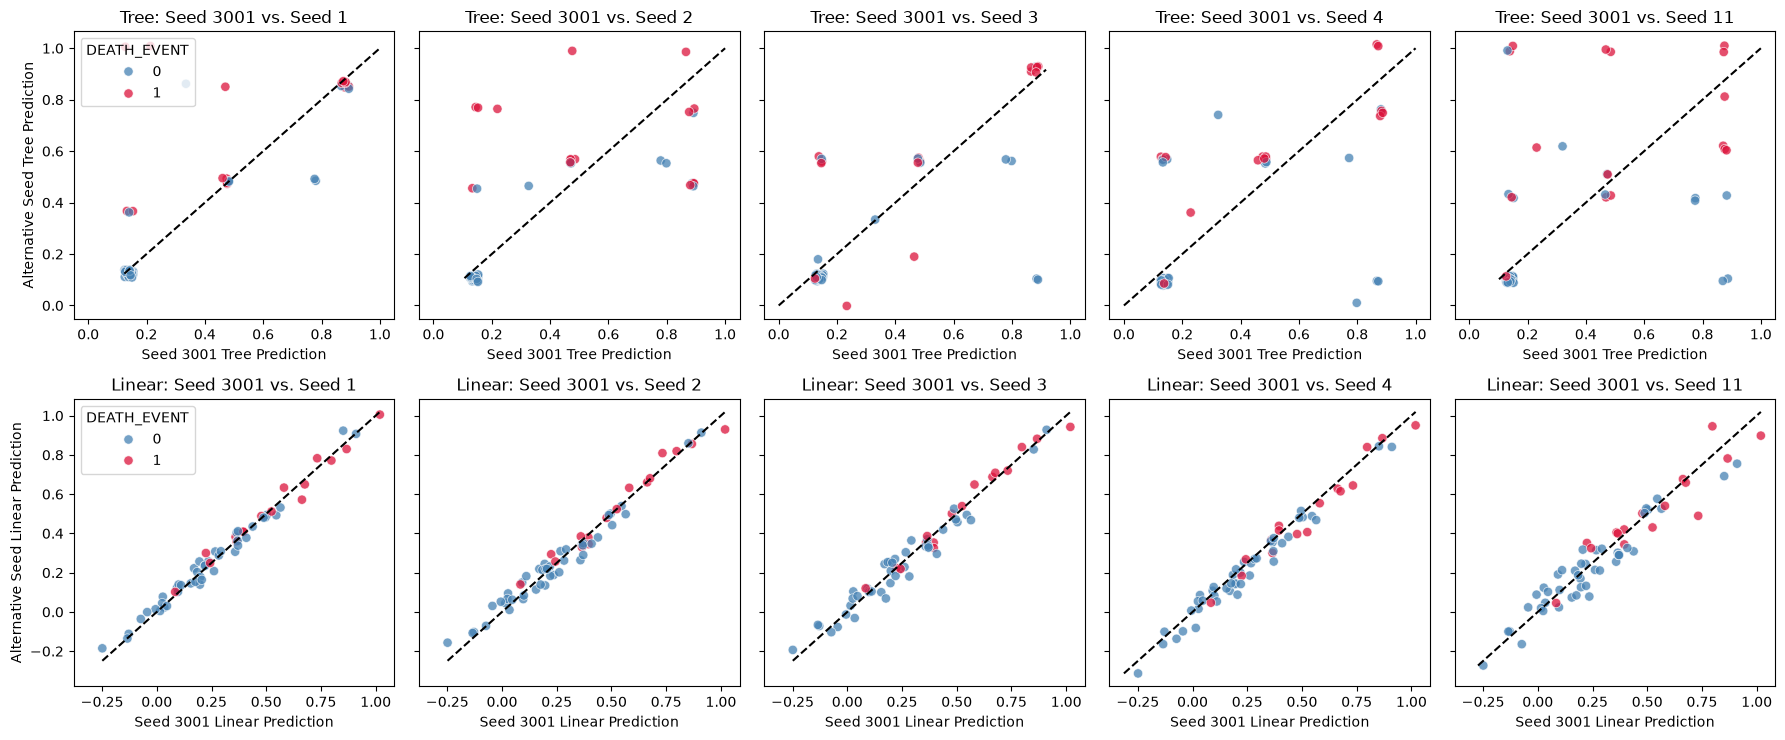

Q4b: Correlation with Question 2 Model Predictions (Seed 3001) on X_test0:


,Tree Correlation,Linear Correlation
Alternative Seed,,
1,0.8047,0.9920
2,0.7078,0.9866
3,0.7524,0.9839
4,0.6420,0.9873
11,0.5052,0.9562
Average,0.6824,0.9812


Q4c: Simple Linear Regression of Alternative Predictions on Seed 3001 Predictions:


,Tree Intercept,Tree Slope,Tree R^2,Linear Intercept,Linear Slope,Linear R^2
Alternative Seed,,,,,,
1,0.0704,0.8786,0.6475,0.0166,0.9631,0.9840
2,0.0961,0.6810,0.5010,0.0190,0.9422,0.9734
3,0.0630,0.7728,0.5661,0.0092,0.9625,0.9680
4,0.0973,0.6479,0.4121,-0.0228,0.9792,0.9748
11,0.1464,0.5582,0.2552,0.0173,0.8903,0.9143
Average,0.0946,0.7077,0.4764,0.0079,0.9475,0.9629


Overlap between X_test0 (60 patients) and each alternative seed's training set:
  Seed  1: 45 / 60 of Q2 test patients were in its training set
  Seed  2: 43 / 60 of Q2 test patients were in its training set
  Seed  3: 47 / 60 of Q2 test patients were in its training set
  Seed  4: 49 / 60 of Q2 test patients were in its training set
  Seed 11: 54 / 60 of Q2 test patients were in its training set

Bootstrap Stability Check (Alternative Models Trained Only on Resamples of X_train0):


,Tree Corr,Tree Slope,Tree R^2,Linear Corr,Linear Slope,Linear R^2
Bootstrap Seed,,,,,,
1,0.8160,1.0776,0.6658,0.9689,1.0361,0.9389
2,0.4429,0.4180,0.1962,0.9804,1.2418,0.9613
3,0.4690,0.5000,0.2199,0.9287,1.0162,0.8625
4,0.9060,1.0760,0.8209,0.9869,1.0985,0.9740
11,0.4662,0.4936,0.2173,0.8670,0.8070,0.7516
Average,0.6200,0.7130,0.4240,0.9464,1.0400,0.8976


In [10]:
# PHASE 2 IMPROVEMENT 3a: Fix shared y-axis label, color by DEATH_EVENT, and jitter overlapping tree points
rng = np.random.default_rng(100)
fig, axes = plt.subplots(2, len(alt_seeds), figsize=(18, 7.5), sharex='row', sharey='row')

for i, s in enumerate(alt_seeds):
    # Top row: Decision Trees (small jitter reveals stacked patients sharing the same leaf value)
    x_jit = tree_preds[main_seed] + rng.uniform(-0.015, 0.015, size=len(tree_preds))
    y_jit = tree_preds[s] + rng.uniform(-0.015, 0.015, size=len(tree_preds))
    sns.scatterplot(
        x=x_jit, y=y_jit, hue=y_test0, palette={0: 'steelblue', 1: 'crimson'},
        alpha=0.75, s=45, ax=axes[0, i], legend=(i == 0)
    )
    t_min = min(tree_preds[main_seed].min(), tree_preds[s].min())
    t_max = max(tree_preds[main_seed].max(), tree_preds[s].max())
    axes[0, i].plot([t_min, t_max], [t_min, t_max], color='black', linestyle='--', linewidth=1.5)
    axes[0, i].set_title(f"Tree: Seed {main_seed} vs. Seed {s}")
    axes[0, i].set_xlabel(f"Seed {main_seed} Tree Prediction")
    
    # Bottom row: Linear Models
    sns.scatterplot(
        x=lm_preds[main_seed], y=lm_preds[s], hue=y_test0, palette={0: 'steelblue', 1: 'crimson'},
        alpha=0.75, s=45, ax=axes[1, i], legend=(i == 0)
    )
    l_min = min(lm_preds[main_seed].min(), lm_preds[s].min())
    l_max = max(lm_preds[main_seed].max(), lm_preds[s].max())
    axes[1, i].plot([l_min, l_max], [l_min, l_max], color='black', linestyle='--', linewidth=1.5)
    axes[1, i].set_title(f"Linear: Seed {main_seed} vs. Seed {s}")
    axes[1, i].set_xlabel(f"Seed {main_seed} Linear Prediction")

axes[0, 0].set_ylabel("Alternative Seed Tree Prediction")
axes[1, 0].set_ylabel("Alternative Seed Linear Prediction")
axes[0, 0].legend(title='DEATH_EVENT', loc='upper left')
axes[1, 0].legend(title='DEATH_EVENT', loc='upper left')
plt.tight_layout()
plt.show()

# Q4b: Correlation between Question 2 model predictions and alternative model predictions
corr_df = pd.DataFrame({
    'Tree Correlation': [tree_preds[main_seed].corr(tree_preds[s]) for s in alt_seeds],
    'Linear Correlation': [lm_preds[main_seed].corr(lm_preds[s]) for s in alt_seeds]
}, index=pd.Index(alt_seeds, name='Alternative Seed'))
corr_df.loc['Average'] = corr_df.mean()

print("Q4b: Correlation with Question 2 Model Predictions (Seed 3001) on X_test0:")
display(corr_df.round(4))

# Q4c: Simple linear regression of alternative model predictions on Question 2 predictions
def slr(x, y):
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    resid = y - (b0 + b1 * x)
    rsq = 1 - np.inner(resid, resid) / np.inner(y - y_bar, y - y_bar)
    return b0, b1, rsq

slr_rows = []
for s in alt_seeds:
    t_b0, t_b1, t_r2 = slr(tree_preds[main_seed], tree_preds[s])
    l_b0, l_b1, l_r2 = slr(lm_preds[main_seed], lm_preds[s])
    slr_rows.append({
        'Alternative Seed': s,
        'Tree Intercept': t_b0,
        'Tree Slope': t_b1,
        'Tree R^2': t_r2,
        'Linear Intercept': l_b0,
        'Linear Slope': l_b1,
        'Linear R^2': l_r2
    })

slr_df = pd.DataFrame(slr_rows).set_index('Alternative Seed')
slr_df.loc['Average'] = slr_df.mean()

print("Q4c: Simple Linear Regression of Alternative Predictions on Seed 3001 Predictions:")
display(slr_df.round(4))

# PHASE 2 IMPROVEMENT 3b: Check train-test overlap and evaluate bootstrap models that never train on X_test0
print("Overlap between X_test0 (60 patients) and each alternative seed's training set:")
for s in alt_seeds:
    _, _, X_tr_s, _, _, _ = fit_models(s)
    overlap = int(X_test0.index.isin(X_tr_s.index).sum())
    print(f"  Seed {s:2d}: {overlap} / {len(X_test0)} of Q2 test patients were in its training set")

boot_rows = []
for s in alt_seeds:
    boot_idx = X_train0.sample(frac=1.0, replace=True, random_state=s).index
    tree_b = DecisionTreeRegressor(max_depth=3, random_state=100).fit(X_train0.loc[boot_idx], y_train0.loc[boot_idx])
    lm_b = LinearRegression().fit(X_train0.loc[boot_idx], y_train0.loc[boot_idx])
    
    tp_b = tree_b.predict(X_test0)
    lp_b = lm_b.predict(X_test0)
    t_b0, t_b1, t_r2 = slr(tree_pred0, tp_b)
    l_b0, l_b1, l_r2 = slr(lm_pred0, lp_b)
    
    boot_rows.append({
        'Bootstrap Seed': s,
        'Tree Corr': np.corrcoef(tree_pred0, tp_b)[0, 1],
        'Tree Slope': t_b1,
        'Tree R^2': t_r2,
        'Linear Corr': np.corrcoef(lm_pred0, lp_b)[0, 1],
        'Linear Slope': l_b1,
        'Linear R^2': l_r2
    })

boot_df = pd.DataFrame(boot_rows).set_index('Bootstrap Seed')
boot_df.loc['Average'] = boot_df.mean()
print("\nBootstrap Stability Check (Alternative Models Trained Only on Resamples of X_train0):")
display(boot_df.round(4))

Before comparing the test predictions, we can see why the linear model coefficients in Question 3 vary by different amounts across features. Raw linear slopes measure the change in predicted death risk for a 1-unit increase in a variable, so their sizes and standard deviations depend on each variable's unit scale. Platelets has a standard deviation of 97,804.24, which makes its per-unit slope and standard deviation across seeds round to 0.000000. Variables measured on small scales like transformed serum creatinine, which has a standard deviation of 0.38, and binary 0 or 1 indicators like diabetes, smoking, anaemia, and sex represent a much larger jump per unit, so their raw standard deviations across seeds are larger at 0.0152 to 0.0526. Once we multiply each slope by 1 standard deviation of its feature, the spread across seeds is small and similar for every predictor, ranging from 0.0048 to 0.0251.

To test whether the models make similar predictions, we compared all five alternative models against the seed 3001 model on the same 60 test patients from Question 2:

* **4a. Scatterplots:** The linear model predictions in the bottom row line up tightly along the 45-degree equality line in all five plots, so they appear very similar. Adding a small jitter to the tree plots in the top row shows how many patients were hidden on top of each other in Phase 1 because a depth-3 tree only outputs 7 or 8 unique leaf values. Several patients who get a predicted risk of 0.14 from the seed 3001 tree get 0.56 to 1.00 from an alternative tree, so the tree predictions are only loosely similar.
* **4b. Correlations:** The linear models are very highly correlated with the seed 3001 linear model, ranging from 0.9562 in seed 11 to 0.9920 in seed 1 with an average correlation of 0.9812. The trees have a moderate to strong positive correlation with the seed 3001 tree, ranging from 0.5052 in seed 11 up to 0.8047 in seed 1 with an average correlation of 0.6824.
* **4c. Simple linear regressions and bootstrap overlap check:** For the linear models, the intercepts are very close to 0 at -0.0228 to +0.0190 with an average of +0.0079, the slopes are very close to 1 at 0.8903 to 0.9792 with an average of 0.9475, and the $R^2$ values are very close to 1 at 0.9143 to 0.9840 with an average of 0.9629. For the decision trees, the intercepts are fairly close to 0 at +0.0630 to +0.1464 with an average of +0.0946, but the slopes fall well below 1 at 0.5582 to 0.8786 with an average of 0.7077, and the $R^2$ values are far from 1 at 0.2552 to 0.6475 with an average of 0.4764. In addition, because each alternative seed re-splits the full 299-row dataset, 43 to 54 of the 60 Question 2 test patients were inside each alternative model's training set. When we instead train the five alternative models on bootstrap resamples of the Question 2 training set so none of them ever see the 60 test patients, average tree correlation drops to 0.6200 and average tree $R^2$ drops to 0.4240, while linear model correlation stays high at 0.9464 with an average $R^2$ of 0.8976.

# Q5:

In [11]:
# PHASE 2 IMPROVEMENT 4a: Quantify per-patient prediction swings across the 6 seeds on X_test0
tree_patient_range = tree_preds.max(axis=1) - tree_preds.min(axis=1)
lm_patient_range = lm_preds.max(axis=1) - lm_preds.min(axis=1)

swing_summary = pd.DataFrame({
    'Mean Patient Risk Range (Max - Min)': [tree_patient_range.mean(), lm_patient_range.mean()],
    'Median Patient Risk Range': [tree_patient_range.median(), lm_patient_range.median()],
    'Max Patient Risk Swing': [tree_patient_range.max(), lm_patient_range.max()],
    'Patients with Swing >= 0.50 (out of 60)': [int((tree_patient_range >= 0.50).sum()), int((lm_patient_range >= 0.50).sum())]
}, index=['Decision Tree (6 Seeds)', 'Linear Model (6 Seeds)'])

print("Individual Test Patient Prediction Stability Across All 6 Seeds:")
display(swing_summary.round(4))

Individual Test Patient Prediction Stability Across All 6 Seeds:


,Mean Patient Risk Range (Max - Min),Median Patient Risk Range,Max Patient Risk Swing,Patients with Swing >= 0.50 (out of 60)
Decision Tree (6 Seeds),0.2618,0.0468,1.0000,12
Linear Model (6 Seeds),0.1108,0.1033,0.3195,0


Linear models have very similar coefficients and nearly identical predictions across train-test splits. Ordinary least squares computes its slopes using averages across all 239 training patients at once, so swapping 20 percent of the rows barely changes the weights on major predictors like transformed serum creatinine, ejection fraction, age, and serum sodium. Their test predictions have an average correlation of 0.9812 and an average regression $R^2$ of 0.9629 across seeds. Across all six splits, the average test patient's predicted death risk varies by only 0.1108 from lowest to highest in the linear models, and not a single patient swings by 0.50 or more.

Decision trees do not have stable structures across splits, and their predictions are only moderately similar. Because a tree picks greedy binary splits one step at a time, a small change in the training set can move the root cutoff on transformed serum creatinine or switch the root variable to ejection fraction, which changes all the branches and leaf averages below it. The trees still rely on the same main clinical risk factors, so their predictions correlate positively at an average of 0.6824, but patients near a cutoff boundary can land in a completely different leaf from one seed to the next. Across the six trees, the average test patient's predicted risk swings by 0.2618, and 12 of the 60 test patients swing by 0.50 or more, including a maximum swing of 1.0000 for a patient predicted at 0.00 death risk in one tree and 1.00 in another.

# Q6:

In [12]:
from sklearn.ensemble import RandomForestRegressor

# PHASE 2 IMPROVEMENT 4b: Verify whether averaging 200 depth-3 trees (Random Forest) stabilizes predictions across splits
rf0 = RandomForestRegressor(n_estimators=200, max_depth=3, random_state=100).fit(X_train0, y_train0)
rf_pred0 = rf0.predict(X_test0)

rf_rows = []
for s in alt_seeds:
    X_tr_s, _, y_tr_s, _ = train_test_split(X, y, test_size=0.2, random_state=s)
    rf_s = RandomForestRegressor(n_estimators=200, max_depth=3, random_state=100).fit(X_tr_s, y_tr_s)
    rf_p = rf_s.predict(X_test0)
    b0, b1, r2 = slr(rf_pred0, rf_p)
    rf_rows.append({
        'Alternative Seed': s,
        'RF Correlation': np.corrcoef(rf_pred0, rf_p)[0, 1],
        'RF Intercept': b0,
        'RF Slope': b1,
        'RF R^2': r2
    })

rf_df = pd.DataFrame(rf_rows).set_index('Alternative Seed')
rf_df.loc['Average'] = rf_df.mean()
print("Random Forest (200 Depth-3 Trees) Prediction Stability Across Splits on X_test0:")
display(rf_df.round(4))

Random Forest (200 Depth-3 Trees) Prediction Stability Across Splits on X_test0:


,RF Correlation,RF Intercept,RF Slope,RF R^2
Alternative Seed,,,,
1,0.9432,0.0084,1.0314,0.8896
2,0.9386,-0.0007,1.0288,0.8811
3,0.9327,0.0164,0.9673,0.8699
4,0.9116,0.0100,0.9422,0.8310
11,0.8832,0.0178,0.9233,0.7801
Average,0.9219,0.0104,0.9786,0.8503


This statement is **partially true in overall direction, but false if "very similar" means close agreement on individual patients** for the decision trees in this dataset.

On the true side, two trees with very different branches still split on the same core health measures: kidney function, heart pumping fraction, serum sodium, and age. Even when seed 3001 splits first on transformed serum creatinine and seed 11 splits first on ejection fraction, a patient with bad kidney numbers and low ejection fraction lands in a high-risk leaf in both trees. That shared signal keeps the tree predictions positively correlated between 0.5052 and 0.8047, with an average correlation of 0.6824, while the linear models stay above 0.9562 correlation in every split.

Calling the tree predictions "very similar" goes too far on this dataset. With only 299 patients in total and 239 in each training split, single trees have high prediction variance. Moving a few patients in or out of the training set changes the split thresholds and leaf averages enough that the simple linear regression $R^2$ between tree predictions averages just 0.4764 and drops to 0.2552 in seed 11, and 12 of the 60 test patients see their predicted risk change by at least 50 percentage points across the six trees. When we instead average 200 depth-3 trees using a Random Forest across the exact same splits, the average correlation between splits jumps from 0.6824 to 0.9219, the average slope moves to 0.9786, and the average regression $R^2$ rises from 0.4764 to 0.8503, confirming that ensembling cures most of the split-to-split instability of single trees.

### *Reflection on AI assistance
In your own words without generative AI.

The AI was overall helpful. For Q1, it added a check that found 59 unique rows with repeated platelet or CPK numbers, and it put in a correlation heatmap. In Q2, it decided to add a 5-fold CV to back up the `max_depth=3` choice and checked how many linear predictions fell outside the 0 to 1 bounds. For Q4, it fixed the shared y-axis label, added jitter and color to the points, and wrote a quick check for bootstrap overlap. In Q5 and Q6, it measured how much individual patient risk estimates swung across splits and how a Random Forest calmed that variance down. Two of the AI's ideas would have messed up the notebook if I had used them: In Q1, it suggested to drop every row with the repeated platelet value of 263358.03 or CPK value of 582. That would have thrown out 59 of the 299 patients and made our small-sample noise much worse. In Q3, it wanted to re-tune `max_depth` and `min_samples_leaf` on every random seed, which would have mixed up hyperparameter changes with data-split noise. I checked all the code I kept by looking at the printed numbers from phase 1 and comparing the output to verify the final solution. On `X_train0`, 5-fold CV peaked at `max_depth=3` with a CV RMSE of 0.4413 and a CV $R^2$ of 0.1021. My overlap check showed that 43 to 54 of the 60 test patients showed up in the other training sets, and the single tree $R^2$ fell from 0.4764 to 0.4240 when using bootstrap draws. There doesn't seem to be any remaining concerns from us. 